In [1]:
# ============================== CONFIG — edit paths ==============================
import os, sys, json, re, glob, shutil, zipfile, random, warnings, itertools, math, time, copy
# PyTorch >= 2.6 defaults torch.load(weights_only=True); OpenMMLab checkpoints (and mmengine's own checkpoints)
# store numpy objects, so they need the old behaviour. Only load checkpoints you trust (official / your own).
os.environ.setdefault("TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD", "1")
from pathlib import Path
from collections import Counter, defaultdict

def _p(env, default):
    return Path(os.environ.get(env, default)).expanduser()

DATA_DIR = _p("SYRIP_DIR", "~/scratch/SyRIP")                        # an already-extracted dataset folder (used if it exists)
ZIP_PATH = _p("SYRIP_ZIP", "~/scratch/expanded_SyRIP.zip")            # otherwise a zip; password via $SYRIP_ZIP_PASSWORD or prompt
CKPT_DIR = _p("CKPT_DIR",  "~/scratch/mmpose_ckpts")                   # `mim download` destination
PROJECT  = _p("PROJECT",   "~/scratch/infant_symmetry")                # persistent outputs (scratch is purged after 60 days)


SEED       = 0
N_FOLDS    = 5
USE_SYNTHETIC  = True     # add SyRIP synthetic images (if present in the zip) to every training fold
USE_EXTRA_REAL = True     # add real annotated images not among the 700 rated ones (if any) to training

# Pose models to fine-tune (MMPose config names = `mim download` names)
POSE_MODELS = {
    "RTMPose-S": dict(config="rtmpose-s_8xb256-420e_coco-256x192",      epochs=120, lr=5e-4, batch=64),
    "HRNet-W32": dict(config="td-hm_hrnet-w32_8xb64-210e_coco-256x192", epochs=80,  lr=2e-4, batch=32),
}
RUN_TRAINING             = True    # fine-tune all (model, fold) runs here; finished runs are skipped, interrupted ones resume
RUN_POSE_INFERENCE       = True    # requires mmpose + trained checkpoints
ROBUSTNESS_SUBSET        = "test100"   # "test100" | "all"
CLS_SEEDS                = [0, 1, 2]   # seeds for MLP / GNN symmetry classifiers

OUT = PROJECT / "outputs"; FIG = PROJECT / "figures"
for d in [PROJECT, OUT, FIG]:
    d.mkdir(parents=True, exist_ok=True)
print("DATA_DIR:", DATA_DIR, DATA_DIR.exists())
print("ZIP     :", ZIP_PATH, ZIP_PATH.exists())
print("CKPT_DIR:", CKPT_DIR, CKPT_DIR.exists())
print("PROJECT :", PROJECT)

DATA_DIR: /home/dpraju90/scratch/SyRIP True
ZIP     : /home/dpraju90/scratch/expanded_SyRIP.zip True
CKPT_DIR: /home/dpraju90/scratch/mmpose_ckpts True
PROJECT : /home/dpraju90/scratch/infant_symmetry


In [2]:
import sys, onnxruntime as ort, tensorrt as trt
print(sys.executable, trt.__version__, ort.get_available_providers())

/home/dpraju90/envs/infsym/bin/python 10.13.3.9.post1 ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']


In [3]:
   import sys, torch, cv2, mmcv, mmpose
   print(sys.executable, torch.cuda.is_available(), cv2.__version__, mmcv.__version__, mmpose.__version__)

/home/dpraju90/envs/infsym/bin/python True 4.11.0 2.1.0 1.3.2


In [4]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import (roc_auc_score, roc_curve, cohen_kappa_score, f1_score,
                             confusion_matrix, accuracy_score)
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160, "display.max_columns", 30)

def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s)
    try:
        import torch; torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    except ImportError:
        pass
seed_everything()

try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    HAVE_TORCH = True
except ImportError:
    HAVE_TORCH, DEVICE = False, "cpu"
try:
    import mmpose, mmcv, mmengine
    HAVE_MMPOSE = True
    print("mmpose", mmpose.__version__, "| mmcv", mmcv.__version__)
except Exception as e:
    HAVE_MMPOSE = False
    print("mmpose not importable here ->", type(e).__name__, e)
print("torch:", HAVE_TORCH, "| device:", DEVICE)

# COCO-17 layout used everywhere for 2D
KP_NAMES = ['nose','l_eye','r_eye','l_ear','r_ear','l_shoulder','r_shoulder','l_elbow','r_elbow',
            'l_wrist','r_wrist','l_hip','r_hip','l_knee','r_knee','l_ankle','r_ankle']
FLIP_PERM = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]
COCO_IDX = dict(ls=5, rs=6, le=7, re=8, lw=9, rw=10, lh=11, rh=12, lk=13, rk=14, la=15, ra=16)
# 14-joint LSP order used by HW-HuP / SPIN outputs in the authors' repo
LSP_IDX  = dict(ra=0, rk=1, rh=2, lh=3, lk=4, la=5, rw=6, re=7, rs=8, ls=9, le=10, lw=11)
LIMBS = ["upper_arm", "lower_arm", "upper_leg", "lower_leg"]
# (left proximal, left distal, right proximal, right distal) for each limb pair, by COCO index
LIMB_JOINTS = {"upper_arm": (5, 7, 6, 8), "lower_arm": (7, 9, 8, 10),
               "upper_leg": (11, 13, 12, 14), "lower_leg": (13, 15, 14, 16)}
SKELETON = [(0,1),(0,2),(1,3),(2,4),(5,6),(5,7),(7,9),(6,8),(8,10),(5,11),(6,12),(11,12),
            (11,13),(13,15),(12,14),(14,16),(0,5),(0,6)]
MIRROR_EDGES = [(1,2),(3,4),(5,6),(7,8),(9,10),(11,12),(13,14),(15,16)]

mmpose 1.3.2 | mmcv 2.1.0
torch: True | device: cuda


In [5]:
def extract_zip(zpath, dest):
    """Extract, asking for a password only if the archive is encrypted (ZipCrypto; AES zips need `7z x`)."""
    with zipfile.ZipFile(zpath) as z:
        encrypted = any(i.flag_bits & 0x1 for i in z.infolist())
        pwd = None
        if encrypted:
            import getpass
            pwd = (os.environ.get("SYRIP_ZIP_PASSWORD") or getpass.getpass(f"password for {zpath.name}: ")).encode()
        try:
            z.extractall(dest, pwd=pwd)
        except NotImplementedError:
            raise RuntimeError("AES-encrypted zip: extract in a terminal with `module load p7zip; 7z x <zip>` "
                               "and point SYRIP_DIR at the folder")

if DATA_DIR.exists():
    DATA_ROOT = DATA_DIR
    print("using extracted folder", DATA_ROOT)
else:
    DATA_ROOT = PROJECT / "data" / ZIP_PATH.stem          # on scratch so SLURM batch jobs can read it too
    if not ZIP_PATH.exists() and not (DATA_ROOT / ".unzipped").exists():
        raise FileNotFoundError(f"neither {DATA_DIR} nor {ZIP_PATH} exists — set DATA_DIR or ZIP_PATH")
    if not (DATA_ROOT / ".unzipped").exists():
        t0 = time.time()
        DATA_ROOT.mkdir(parents=True, exist_ok=True)
        extract_zip(ZIP_PATH, DATA_ROOT)
        for inner in list(DATA_ROOT.rglob("*.zip")):      # nested zips
            extract_zip(inner, inner.with_suffix(""))
        (DATA_ROOT / ".unzipped").touch()
        print(f"unzipped in {time.time()-t0:.0f}s")

ALL_FILES = [Path(dp) / f for dp, _, fs in os.walk(DATA_ROOT) for f in fs if not f.startswith("._")]
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
print(f"{len(ALL_FILES)} files under {DATA_ROOT}")

def find(pattern, contains=None, required=False):
    pat = re.compile(pattern, re.I)
    hits = [f for f in ALL_FILES if pat.search(f.name) and (contains is None or contains.lower() in str(f).lower())]
    hits.sort(key=lambda p: (len(p.parts), str(p)))
    if required and not hits:
        raise FileNotFoundError(f"no file matching {pattern!r} under {DATA_ROOT}")
    return hits[0] if hits else None

tree = Counter()
for f in ALL_FILES:
    rel_parts = f.relative_to(DATA_ROOT).parts
    tree[("/".join(rel_parts[:min(4, len(rel_parts) - 1)]) or ".", f.suffix.lower())] += 1
print(pd.DataFrame([(d, e, n) for (d, e), n in tree.items()], columns=["dir", "ext", "n"])
      .sort_values("dir").to_string(index=False)[:4000])

# optional extras: picked up automatically if they happen to be inside the zip
PATHS = dict(
    survey   = find(r"^asymmetryanalysis.*\.xlsx$"),
    name_map = find(r"^img_name700_map\.npy$"),
    fidip    = find(r"^keypoints_validate_infant_results.*\.json$"),
    p3d      = find(r"^output_pose_3D\.npy$"),
    p3d_names= find(r"^output_imgnames\.npy$"),
    c3d      = find(r"^correct_3D\.npy$"),
)
for k, v in PATHS.items():
    print(f"{k:10s} {v if v else '-- not in zip'}")

using extracted folder /home/dpraju90/scratch/SyRIP
2009 files under /home/dpraju90/scratch/SyRIP
                    dir   ext    n
                      .  .zip    3
                      .   .md    1
      annotations/1000S .json    1
       annotations/200R .json    1
 annotations/200R_1000S .json    1
annotations/validate100 .json    1
annotations/validate500 .json    1
    images/train_infant  .jpg 1500
 images/validate_infant  .jpg  500
survey     -- not in zip
name_map   -- not in zip
fidip      -- not in zip
p3d        -- not in zip
p3d_names  -- not in zip
c3d        -- not in zip


In [6]:
# --- every COCO keypoint annotation file in the zip -> pool of real and synthetic images
def load_coco(path):
    with open(path) as f:
        return json.load(f)

by_name = defaultdict(list)
for f in ALL_FILES:
    if f.suffix.lower() in IMG_EXT:
        by_name[f.name].append(f)

def resolve_image(im, json_path):
    """Find the file for a COCO image entry: match basename, disambiguate by image size and folder proximity."""
    cands = by_name.get(Path(im["file_name"]).name, [])
    if len(cands) > 1:
        from PIL import Image
        same = [c for c in cands if Image.open(c).size == (im.get("width"), im.get("height"))]
        cands = same or cands
        jp = json_path.parent.parts
        cands = sorted(cands, key=lambda c: -sum(1 for a, b in zip(c.parts, jp) if a == b))
    return cands[0] if cands else None

def is_synthetic(im):
    return bool(im.get("is_synthetic", False)) or Path(im["file_name"]).name.lower().startswith("syn")

kp_jsons = [f for f in ALL_FILES if f.suffix == ".json" and "result" not in f.name.lower()]
REAL, SYN, COCO_CATEGORIES = {}, {}, None
for jf in sorted(kp_jsons):
    try:
        g = load_coco(jf)
    except Exception:
        continue
    if not (isinstance(g, dict) and g.get("annotations") and "keypoints" in g["annotations"][0]):
        continue
    COCO_CATEGORIES = COCO_CATEGORIES or g.get("categories")
    a_by = defaultdict(list)
    for a in g["annotations"]:
        a_by[a["image_id"]].append(a)
    n_new = 0
    for im in g["images"]:
        anns = a_by.get(im["id"], [])
        if len(anns) != 1 or len(anns[0]["keypoints"]) != 51:
            continue                                  # single-infant, 17-keypoint images only
        key = im.get("original_file_name") or Path(im["file_name"]).name
        pool = SYN if is_synthetic(im) else REAL
        if key in pool:
            continue
        path = resolve_image(im, jf)
        if path is None:
            continue
        pool[key] = dict(im=im, ann=anns[0], path=path, json=jf)
        n_new += 1
    print(f"{jf.relative_to(DATA_ROOT)}: +{n_new}")
assert COCO_CATEGORIES is not None and REAL, "no COCO keypoint annotations with resolvable images found in the zip"
print(f"real images: {len(REAL)} | synthetic images: {len(SYN)}")

annotations/1000S/person_keypoints_train_infant.json: +1000
annotations/200R/person_keypoints_train_infant.json: +200
annotations/200R_1000S/person_keypoints_train_infant.json: +0
annotations/validate100/person_keypoints_validate_infant.json: +100
annotations/validate500/person_keypoints_validate_infant.json: +400
real images: 700 | synthetic images: 1000


In [7]:
# --- master table of the real images used for evaluation (survey order if the survey map is present)
def natural(s):
    return [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", s)]

ORIG_NAMES, SURVEY_ORDER = None, False
if PATHS["name_map"] is not None:
    nm = np.load(PATHS["name_map"]).astype(str)
    if set(nm[:, 1]) <= set(REAL):
        ORIG_NAMES, SURVEY_ORDER = list(nm[:, 1]), True
        ORIG2SURVEY = dict(zip(nm[:, 1], nm[:, 0]))
    else:
        print("name map found but its images are not all in the zip -> ignoring the survey")
if ORIG_NAMES is None:
    ORIG_NAMES = sorted(REAL, key=natural)
N_IMG = len(ORIG_NAMES)

recs = [REAL[n] for n in ORIG_NAMES]
GT_KP = np.array([r["ann"]["keypoints"] for r in recs], float).reshape(N_IMG, 17, 3)
VIS = GT_KP[:, :, 2] > 0

def kp_bbox(kp, w, h, pad=0.15):
    """xywh box around labelled joints (+pad), clipped to the image. SyRIP's stored boxes/areas are unreliable."""
    v = kp[:, 2] > 0
    xs, ys = kp[v, 0], kp[v, 1]
    x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
    pw, ph = (x1 - x0) * pad + 5, (y1 - y0) * pad + 5
    x0, y0 = max(0, x0 - pw), max(0, y0 - ph)
    x1, y1 = min(w - 1, x1 + pw), min(h - 1, y1 + ph)
    return np.array([x0, y0, x1 - x0, y1 - y0])

META = pd.DataFrame({
    "idx": np.arange(N_IMG), "orig_name": ORIG_NAMES,
    "img_path": [str(r["path"]) for r in recs],
    "width": [r["im"]["width"] for r in recs], "height": [r["im"]["height"] for r in recs],
    "posture": [r["im"].get("posture", "NA") for r in recs],
    "source": [r["im"].get("image_source", "") or "" for r in recs],
})
META["bbox"] = [kp_bbox(GT_KP[i], META.width[i], META.height[i]) for i in range(N_IMG)]
META["test100"] = META.orig_name.isin([f"test{i}.jpg" for i in range(100)])
META["syrip_test500"] = META.orig_name.str.startswith("test")
META["group"] = [s if s else f"solo_{i}" for i, s in enumerate(META.source)]   # group = source video
print(META[["orig_name", "posture", "test100", "syrip_test500"]].head())
print("images:", N_IMG, "| video groups:", META.group.nunique(), "| largest group:", META.group.value_counts().iloc[0])
print(META.posture.value_counts().to_dict())

# extra training-only images: all synthetic ones (+ any real ones not in the evaluation table)
EXTRA = [(r["path"], r["im"], r["ann"], "synthetic") for r in SYN.values()]
EXTRA += [(r["path"], r["im"], r["ann"], "real") for k, r in REAL.items() if k not in set(ORIG_NAMES)]
print("extra training images:", Counter(k for *_, k in EXTRA))

   orig_name posture  test100  syrip_test500
0  test0.jpg      NA     True           True
1  test1.jpg      NA     True           True
2  test2.jpg      NA     True           True
3  test3.jpg      NA     True           True
4  test4.jpg      NA     True           True
images: 700 | video groups: 302 | largest group: 57
{'NA': 700}
extra training images: Counter({'synthetic': 1000})


In [8]:
# --- grouped K folds (by source video), stratified by posture, shared by pose models and symmetry classifiers
from sklearn.model_selection import StratifiedGroupKFold
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLD = np.full(N_IMG, -1)
for k, (_, te) in enumerate(sgkf.split(np.zeros(N_IMG), META.posture, groups=META.group)):
    FOLD[te] = k
META["fold"] = FOLD
print(pd.crosstab(META.fold, META.posture, margins=True))
assert META.groupby("group").fold.nunique().max() == 1, "a video leaked across folds"
ROW_IMG  = np.repeat(np.arange(N_IMG), 4)      # label rows are image-major, limb-minor: row 4*i + l
ROW_LIMB = np.tile(np.arange(4), N_IMG)
ROW_FOLD = FOLD[ROW_IMG]

posture   NA  All
fold             
0        122  122
1        122  122
2        172  172
3        129  129
4        155  155
All      700  700


In [9]:
# --- symmetry geometry (paper Sec. 3.1). The right segment is mirrored across the mid-perpendicular line/plane
# of the shoulder (arms) or hip (legs) segment and compared with the left one. Reflection is affine, so mirroring
# both endpoints equals reflecting the bone vector with H = I - 2nn^T.
def _unit(v):
    return v / (np.linalg.norm(v, axis=-1, keepdims=True) + 1e-9)

def _angle(u, v):
    return np.degrees(np.arccos(np.clip((_unit(u) * _unit(v)).sum(-1), -1, 1)))

def limb_angles(P, J=COCO_IDX):
    """P: (N, joints, 2 or 3). Returns (N, 4) bilateral angle differences in degrees (upper/lower arm, upper/lower leg)."""
    P = np.asarray(P, float)
    def refl(v, n):
        return v - 2 * (v * n).sum(-1, keepdims=True) * n
    ns = _unit(P[:, J["ls"]] - P[:, J["rs"]])
    nh = _unit(P[:, J["lh"]] - P[:, J["rh"]])
    ua = _angle(P[:, J["le"]] - P[:, J["ls"]], refl(P[:, J["re"]] - P[:, J["rs"]], ns))
    la = _angle(P[:, J["lw"]] - P[:, J["le"]], refl(P[:, J["rw"]] - P[:, J["re"]], ns))
    ul = _angle(P[:, J["lk"]] - P[:, J["lh"]], refl(P[:, J["rk"]] - P[:, J["rh"]], nh))
    ll = _angle(P[:, J["la"]] - P[:, J["lk"]], refl(P[:, J["ra"]] - P[:, J["rk"]], nh))
    return np.stack([ua, la, ul, ll], 1)

def angle_class(a):
    return np.digitize(a, [30, 60])          # 0: <30, 1: 30-59, 2: >=60

In [10]:
def kripp_alpha(data, metric="nominal"):
    """Krippendorff's alpha. data: (raters, units), NaN = missing."""
    vals = np.unique(data[~np.isnan(data)])
    C = np.stack([(data == v).sum(0) for v in vals], 1).astype(float)  # (units, values)
    m = C.sum(1); C = C[m >= 2]; m = m[m >= 2]
    Cw = C / (m - 1)[:, None]
    O = Cw.T @ C - np.diag(Cw.sum(0))                                   # coincidence matrix
    nc = O.sum(1); n = nc.sum()
    if metric == "nominal":
        D = 1.0 - np.eye(len(vals))
    elif metric == "interval":
        D = (vals[:, None] - vals[None, :]) ** 2
    elif metric == "ordinal":
        cs = np.concatenate([[0], np.cumsum(nc)])
        D = np.zeros((len(vals),) * 2)
        for a in range(len(vals)):
            for b in range(len(vals)):
                lo, hi = min(a, b), max(a, b)
                D[a, b] = (cs[hi + 1] - cs[lo] - (nc[a] + nc[b]) / 2) ** 2
    Do = (O * D).sum() / n
    De = (np.outer(nc, nc) * D).sum() / (n * (n - 1))
    return 1 - Do / De

def raykar_em(Y, prior_sens=(2, 2), prior_spec=(2, 2), prior_prev=(2, 2), n_iter=200, tol=1e-8):
    """Binary MAP-EM of Raykar et al. (JMLR 2010) with Beta priors. Y: (N, R) in {0,1}.
    Returns posterior P(z=1) per item, rater sensitivities and specificities.
    (The authors' script never resets its likelihood accumulators between iterations; this is the textbook version.)"""
    Y = Y.astype(float)
    mu = Y.mean(1)
    (a1, a2), (b1, b2), (p1, p2) = prior_sens, prior_spec, prior_prev
    eps = 1e-9
    for it in range(n_iter):
        alpha = (a1 - 1 + mu @ Y) / (a1 + a2 - 2 + mu.sum())
        beta  = (b1 - 1 + (1 - mu) @ (1 - Y)) / (b1 + b2 - 2 + (1 - mu).sum())
        alpha, beta = np.clip(alpha, eps, 1 - eps), np.clip(beta, eps, 1 - eps)
        p = np.clip((p1 - 1 + mu.sum()) / (p1 + p2 - 2 + len(mu)), eps, 1 - eps)
        la = Y @ np.log(alpha) + (1 - Y) @ np.log(1 - alpha)
        lb = (1 - Y) @ np.log(beta) + Y @ np.log(1 - beta)
        new = 1 / (1 + np.exp(-(la + np.log(p) - lb - np.log(1 - p))))
        done = np.abs(new - mu).max() < tol
        mu = new
        if done:
            break
    return mu, alpha, beta, p

def avg_kappa_vs_raters(labels, ordinal=False, exclude=None):
    w = "quadratic" if ordinal else None
    ref = ANG if ordinal else SYM
    off = 1 if ordinal else 0
    ks = [cohen_kappa_score(labels, ref[:, r] - off, weights=w) for r in range(10) if r != exclude]
    return float(np.mean(ks))

In [11]:
HAVE_SURVEY = PATHS["survey"] is not None and SURVEY_ORDER
LABEL_MODE = "human" if HAVE_SURVEY else "geometric"
GEO_THRESHOLD = 39.1          # paper's kappa-optimal threshold for ground-truth 2D poses (Table 2)
print("LABEL_MODE =", LABEL_MODE)

if HAVE_SURVEY:
    survey = pd.read_excel(PATHS["survey"])
    SYM = survey[[f"Rater{r}Symmetry"   for r in range(1, 11)]].to_numpy(float)   # (4N, 10), 1 = symmetric
    ANG = survey[[f"Rater{r}AngelRange" for r in range(1, 11)]].to_numpy(float)   # (4N, 10), 1/2/3 [sic] column name
    assert SYM.shape == (4 * N_IMG, 10)
    if "Posture" in survey and (META.posture != "NA").all():
        assert (survey.Posture.values[::4] == META.posture.values).all(), "survey/image order mismatch"
    rel = pd.DataFrame({"symmetry (nominal)": [kripp_alpha(SYM.T, "nominal")],
                        "angle class (interval)": [kripp_alpha(ANG.T, "interval")],
                        "angle class (ordinal)": [kripp_alpha(ANG.T, "ordinal")]}, index=["Krippendorff alpha"])
    print(rel.round(3), "\n(paper: 0.18 symmetry, 0.30 angle)")

    mu_sym, sens_r, spec_r, prev_sym = raykar_em(SYM)
    BAYES_SYM = (mu_sym > 0.5).astype(int)
    mu_gt1, *_ = raykar_em((ANG > 1).astype(int), (5, 1), (5, 1), (5, 1))
    mu_gt2, *_ = raykar_em((ANG > 2).astype(int), (5, 1), (5, 1), (5, 1))
    P_ANG = np.clip(np.stack([1 - mu_gt1, mu_gt1 - mu_gt2, mu_gt2], 1), 0, 1)
    BAYES_ANG = P_ANG.argmax(1)
    VOTE_SYM = np.ceil(np.median(SYM, 1)).astype(int)
    VOTE_ANG = np.ceil(np.median(ANG, 1)).astype(int) - 1
    tab3 = pd.DataFrame({
        "sensitivity": [((SYM[:, r] == 1) & (BAYES_SYM == 1)).sum() / (BAYES_SYM == 1).sum() for r in range(10)],
        "specificity": [((SYM[:, r] == 0) & (BAYES_SYM == 0)).sum() / (BAYES_SYM == 0).sum() for r in range(10)],
    }, index=[f"R{r}" for r in range(1, 11)]).T
    print("\nEach rater vs Bayesian aggregate (paper Table 3):\n", tab3.round(2))
    kap_h = pd.DataFrame({
        "angle κw": [avg_kappa_vs_raters(ANG[:, r] - 1, True, exclude=r) for r in range(10)],
        "symmetry κ": [avg_kappa_vs_raters(SYM[:, r], False, exclude=r) for r in range(10)],
    }, index=[f"Rater {r}" for r in range(1, 11)])
    kap_h.loc["Human vote"] = [avg_kappa_vs_raters(VOTE_ANG, True), avg_kappa_vs_raters(VOTE_SYM)]
    kap_h.loc["Bayesian aggregate"] = [avg_kappa_vs_raters(BAYES_ANG, True), avg_kappa_vs_raters(BAYES_SYM)]
    print(kap_h.round(2))
else:
    A_GT = limb_angles(GT_KP[:, :, :2]).reshape(-1)
    BAYES_SYM = (A_GT < GEO_THRESHOLD).astype(int)          # kept under this name so later cells are mode-agnostic
    BAYES_ANG = angle_class(A_GT)
    mu_sym = BAYES_SYM.astype(float)
    limb_ok = np.stack([VIS[:, list(j)].all(1) for j in LIMB_JOINTS.values()], 1).reshape(-1)
    print(f"geometric labels from GT keypoints: {BAYES_SYM.mean():.1%} symmetric | angle classes {np.bincount(BAYES_ANG)}"
          f" | limb pairs with an unlabelled joint: {(~limb_ok).sum()}")

y_sym, y_ang = BAYES_SYM, BAYES_ANG
pd.DataFrame({"img": ROW_IMG, "orig_name": np.array(ORIG_NAMES)[ROW_IMG], "limb": np.array(LIMBS)[ROW_LIMB],
              "sym": y_sym, "angle_class": y_ang, "label_mode": LABEL_MODE}).to_csv(OUT / "labels.csv", index=False)

LABEL_MODE = geometric
geometric labels from GT keypoints: 48.9% symmetric | angle classes [1134  636 1030] | limb pairs with an unlabelled joint: 11


In [12]:
POSE_DATA = PROJECT / "pose_data"
IMG_LINK_DIR = POSE_DATA / "images"
IMG_LINK_DIR.mkdir(parents=True, exist_ok=True)

def _link(src, name):
    dst = IMG_LINK_DIR / name
    if not dst.exists():
        try:
            os.symlink(os.path.abspath(src), dst)
        except OSError:
            shutil.copy(src, dst)
    return name

def _coco_record(img_id, file_name, w, h, kp17x3, bbox_xywh):
    kp = np.asarray(kp17x3, float).copy()
    kp[kp[:, 2] == 0, :2] = 0
    im = dict(id=int(img_id), file_name=file_name, width=int(w), height=int(h))
    an = dict(id=int(img_id), image_id=int(img_id), category_id=1, iscrowd=0,
              keypoints=kp.reshape(-1).tolist(), num_keypoints=int((kp[:, 2] > 0).sum()),
              bbox=[float(v) for v in bbox_xywh], area=float(bbox_xywh[2] * bbox_xywh[3]))
    return im, an

REAL_RECS = []   # image id = survey index
for i in range(N_IMG):
    name = _link(META.img_path[i], f"real_{i:04d}{Path(META.img_path[i]).suffix}")
    REAL_RECS.append(_coco_record(i, name, META.width[i], META.height[i], GT_KP[i], META.bbox[i]))

EXTRA_RECS = []  # ids from 10000 to avoid clashes
for j, (p, im, an, kind) in enumerate(EXTRA):
    if (kind == "synthetic" and not USE_SYNTHETIC) or (kind == "real" and not USE_EXTRA_REAL):
        continue
    kp = np.asarray(an["keypoints"], float).reshape(17, 3)
    if (kp[:, 2] > 0).sum() < 4:
        continue
    name = _link(p, f"{kind}_{j:05d}{p.suffix}")
    EXTRA_RECS.append(_coco_record(10000 + j, name, im["width"], im["height"], kp, kp_bbox(kp, im["width"], im["height"])))

def write_coco(recs, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        json.dump(dict(images=[r[0] for r in recs], annotations=[r[1] for r in recs], categories=COCO_CATEGORIES), f)
    return path

ANN_DIR = POSE_DATA / "annotations"
GT_ALL_JSON = write_coco(REAL_RECS, ANN_DIR / "real700.json")
FOLD_JSONS = {}
for k in range(N_FOLDS):
    tr = [REAL_RECS[i] for i in range(N_IMG) if FOLD[i] != k] + EXTRA_RECS
    te = [REAL_RECS[i] for i in range(N_IMG) if FOLD[i] == k]
    FOLD_JSONS[k] = (write_coco(tr, ANN_DIR / f"fold{k}_train.json"), write_coco(te, ANN_DIR / f"fold{k}_val.json"))
    print(f"fold {k}: train {len(tr):4d} (extra {len(EXTRA_RECS)}) | val {len(te)}")

fold 0: train 1578 (extra 1000) | val 122
fold 1: train 1578 (extra 1000) | val 122
fold 2: train 1528 (extra 1000) | val 172
fold 3: train 1571 (extra 1000) | val 129
fold 4: train 1545 (extra 1000) | val 155


In [13]:
def find_ckpt(config_name):
    cfgs = sorted(CKPT_DIR.glob(f"{config_name}*.py"))
    # mim names checkpoints differently from configs: match on the model prefix and input size
    size = re.search(r"\d+x\d+", config_name).group(0)
    stem = config_name.split("_")[0]
    pths = [p for p in CKPT_DIR.glob("*.pth") if p.name.startswith(stem) and size in p.name]
    if not cfgs or not pths:
        raise FileNotFoundError(f"run `mim download mmpose --config {config_name} --dest {CKPT_DIR}` on a login node")
    return cfgs[0], pths[0]

def build_finetune_cfg(model_name, k, work_root=PROJECT / "work_dirs"):
    """Turn a COCO-pretrained MMPose config into a SyRIP fold fine-tuning config."""
    from mmengine.config import Config
    spec = POSE_MODELS[model_name]
    cfg_path, ckpt = find_ckpt(spec["config"])
    cfg = Config.fromfile(str(cfg_path))
    tr_json, va_json = FOLD_JSONS[k]
    E = spec["epochs"]

    cfg.load_from = str(ckpt)
    cfg.work_dir = str(work_root / f"{model_name}_fold{k}")
    if cfg.model.backbone.get("init_cfg"):          # avoid internet download on compute nodes
        cfg.model.backbone.init_cfg = None
    cfg.randomness = dict(seed=SEED)
    cfg.auto_scale_lr = dict(enable=False, base_batch_size=spec["batch"])

    cfg.train_cfg.max_epochs = E
    cfg.train_cfg.val_interval = max(1, E // 10)
    cfg.optim_wrapper.optimizer.lr = spec["lr"]
    cfg.param_scheduler = [
        dict(type="LinearLR", start_factor=1e-3, by_epoch=False, begin=0, end=200),
        dict(type="CosineAnnealingLR", eta_min=spec["lr"] * 0.05, begin=E // 3, end=E, T_max=E - E // 3,
             by_epoch=True, convert_to_iter_based=True),
    ]
    for h in cfg.get("custom_hooks", []):
        if "PipelineSwitchHook" in h["type"]:       # RTMPose's stage-2 (weaker aug) switch
            h["switch_epoch"] = E - max(1, E // 7)

    def _ds(dl, ann, test):
        dl.dataset.data_root = ""
        dl.dataset.ann_file = str(ann)
        dl.dataset.data_prefix = dict(img=str(IMG_LINK_DIR) + "/")
        dl.dataset.pop("bbox_file", None)           # use ground-truth boxes (as in the paper)
        dl.dataset.data_mode = "topdown"
        dl.num_workers = min(8, os.cpu_count() or 2)
        dl.persistent_workers = True
        if test:
            dl.dataset.test_mode = True
    _ds(cfg.train_dataloader, tr_json, False); cfg.train_dataloader.batch_size = spec["batch"]
    _ds(cfg.val_dataloader, va_json, True);    cfg.val_dataloader.batch_size = 32
    cfg.test_dataloader = copy.deepcopy(cfg.val_dataloader)
    cfg.val_evaluator = dict(type="CocoMetric", ann_file=str(va_json))
    cfg.test_evaluator = cfg.val_evaluator
    cfg.default_hooks.checkpoint = dict(type="CheckpointHook", interval=cfg.train_cfg.val_interval,
                                        save_best="coco/AP", rule="greater", max_keep_ckpts=1)
    cfg.default_hooks.logger = dict(type="LoggerHook", interval=20)
    out = PROJECT / "configs" / f"{model_name}_fold{k}.py"
    out.parent.mkdir(parents=True, exist_ok=True)
    cfg.dump(str(out))
    return out

def zero_shot_cfg(model_name):
    from mmengine.config import Config
    cfg_path, ckpt = find_ckpt(POSE_MODELS[model_name]["config"])
    cfg = Config.fromfile(str(cfg_path))
    if cfg.model.backbone.get("init_cfg"):
        cfg.model.backbone.init_cfg = None
    return cfg, ckpt

JOBS = []
if HAVE_MMPOSE:
    for m in POSE_MODELS:
        for k in range(N_FOLDS):
            JOBS.append((m, k, build_finetune_cfg(m, k)))
    print(f"{len(JOBS)} fine-tuning configs written to {PROJECT/'configs'}")
else:
    print("mmpose unavailable: configs not generated (run this cell in the infsym environment)")

10 fine-tuning configs written to /home/dpraju90/scratch/infant_symmetry/configs


In [14]:
# --- fine-tuning loop. Each (model, fold) run is independent and restart-safe:
#     DONE marker -> skipped | checkpoint present but not DONE -> resumed | nothing -> starts from the COCO weights
import gc

try:
    import albumentations  # noqa: F401
    HAVE_ALBU = True
except ImportError:
    HAVE_ALBU = False
print("albumentations available:", HAVE_ALBU,
      "" if HAVE_ALBU else "-> RTMPose's Albumentation step (blur + cutout) will be removed from its pipelines")

def strip_albumentation(pipeline):
    """Drop the Albumentation transform(s) from an MMPose pipeline list."""
    return [t for t in pipeline if "Albumentation" not in str(t.get("type", ""))]

def run_dir(m, k):
    return PROJECT / "work_dirs" / f"{m}_fold{k}"

def run_status(m, k):
    wd = run_dir(m, k)
    if (wd / "DONE").exists():
        return "done"
    last = wd / "last_checkpoint"
    if last.exists() and Path(last.read_text().strip()).exists():
        return f"resume ({Path(last.read_text().strip()).stem})"
    return "todo"

def train_one(m, k):
    from mmengine.config import Config
    from mmengine.runner import Runner
    cfg = Config.fromfile(str(PROJECT / "configs" / f"{m}_fold{k}.py"))
    status = run_status(m, k)
    if status == "done":
        return
    if status.startswith("resume"):
        cfg.resume, cfg.load_from = True, None      # continue from work_dir/last_checkpoint (incl. optimizer + epoch)
    else:
        cfg.resume = False                          # start from the COCO-pretrained weights in cfg.load_from

    if not HAVE_ALBU:                               # patch both training pipelines (stage 1 and RTMPose's stage 2)
        cfg.train_dataloader.dataset.pipeline = strip_albumentation(cfg.train_dataloader.dataset.pipeline)
        for h in cfg.get("custom_hooks", []):
            if "PipelineSwitchHook" in h["type"]:
                h["switch_pipeline"] = strip_albumentation(h["switch_pipeline"])

    cfg.default_hooks.logger = dict(type="LoggerHook", interval=50)
    if cfg.get("visualizer"):
        cfg.visualizer.name = f"vis_{m}_{k}_{time.time_ns()}"   # fresh instance per run (mmengine keeps singletons)
    runner = Runner.from_cfg(cfg)
    runner.train()
    (run_dir(m, k) / "DONE").touch()
    del runner
    gc.collect()
    if HAVE_TORCH and DEVICE == "cuda":
        torch.cuda.empty_cache()

if HAVE_MMPOSE:
    status = pd.DataFrame([(m, k, run_status(m, k)) for m in POSE_MODELS for k in range(N_FOLDS)],
                          columns=["model", "fold", "status"])
    print(status.pivot(index="model", columns="fold", values="status"))
if RUN_TRAINING and HAVE_MMPOSE:
    assert DEVICE == "cuda", "training needs a GPU session"
    for m in POSE_MODELS:
        for k in range(N_FOLDS):
            if run_status(m, k) == "done":
                continue
            t0 = time.time()
            print(f"\n========== {m} | fold {k} | {run_status(m, k)} ==========")
            train_one(m, k)
            print(f"========== {m} | fold {k} finished in {(time.time() - t0) / 60:.1f} min ==========")

albumentations available: False -> RTMPose's Albumentation step (blur + cutout) will be removed from its pipelines
fold          0     1     2     3     4
model                                  
HRNet-W32  done  done  done  done  done
RTMPose-S  done  done  done  done  done


In [15]:
import os
os.environ.setdefault("TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD", "1")

'1'

In [16]:
CORRUPTIONS = ["clean", "occlude_limb", "dark", "bright", "blur", "noise", "rotate15"]

def corrupt(img, kind, kp, bbox, rng):
    """Returns corrupted image, transformed GT keypoints, transformed xyxy bbox and (for occlusion) the target joint."""
    import cv2
    h, w = img.shape[:2]
    x0, y0, bw, bh = bbox
    out, kp2, box = img.copy(), kp.copy(), np.array([x0, y0, x0 + bw, y0 + bh], float)
    target = -1
    if kind == "occlude_limb":                       # gray box over one distal limb joint
        cand = [j for j in (7, 8, 9, 10, 13, 14, 15, 16) if kp[j, 2] > 0]
        target = int(rng.choice(cand))
        s = int(0.25 * max(bw, bh)); cx, cy = kp[target, :2].astype(int)
        out[max(0, cy - s // 2):cy + s // 2, max(0, cx - s // 2):cx + s // 2] = img.reshape(-1, 3).mean(0)
    elif kind == "dark":
        out = np.clip(img.astype(float) * 0.35, 0, 255).astype(np.uint8)
    elif kind == "bright":
        out = np.clip(img.astype(float) * 1.6 + 40, 0, 255).astype(np.uint8)
    elif kind == "blur":
        k = max(3, int(0.03 * max(bw, bh)) | 1)
        out = cv2.GaussianBlur(img, (k, k), 0)
    elif kind == "noise":
        out = np.clip(img.astype(float) + rng.normal(0, 25, img.shape), 0, 255).astype(np.uint8)
    elif kind == "rotate15":
        c = (x0 + bw / 2, y0 + bh / 2)
        M = cv2.getRotationMatrix2D(c, 15, 1.0)
        out = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_CONSTANT)
        kp2[:, :2] = np.c_[kp[:, :2], np.ones(17)] @ M.T
        corners = np.array([[box[0], box[1], 1], [box[2], box[1], 1], [box[0], box[3], 1], [box[2], box[3], 1]]) @ M.T
        box = np.r_[corners.min(0), corners.max(0)]
        box = np.clip(box, 0, [w - 1, h - 1, w - 1, h - 1])
    return out, kp2, box, target

def predict_one(model, img, box_xyxy, flip_test=True):
    from mmpose.apis import inference_topdown
    model.test_cfg["flip_test"] = flip_test
    r = inference_topdown(model, img, bboxes=np.asarray(box_xyxy, float)[None], bbox_format="xyxy")[0]
    return r.pred_instances.keypoints[0].astype(float), r.pred_instances.keypoint_scores[0].astype(float)

def run_inference(model_name, mode):
    """mode = 'finetuned' (per-fold best checkpoints, OOF) or 'zeroshot' (COCO checkpoint for all images)."""
    import cv2
    from mmpose.apis import init_model
    from mmengine.config import Config
    rob_idx = set(np.where(META.test100)[0]) if ROBUSTNESS_SUBSET == "test100" else set(range(N_IMG))
    res = dict(kp=np.zeros((N_IMG, 17, 2)), sc=np.zeros((N_IMG, 17)),
               kp_raw=np.zeros((N_IMG, 17, 2)), kp_flip=np.zeros((N_IMG, 17, 2)), sc_flip=np.zeros((N_IMG, 17)),
               rob={c: {} for c in CORRUPTIONS})
    rng = np.random.default_rng(SEED)
    for k in range(N_FOLDS if mode == "finetuned" else 1):
        if mode == "finetuned":
            cfg = Config.fromfile(str(PROJECT / "configs" / f"{model_name}_fold{k}.py"))
            best = sorted(Path(cfg.work_dir).glob("best_coco_AP*.pth"))
            if not (Path(cfg.work_dir) / "DONE").exists():
                raise FileNotFoundError(f"training of {model_name} fold {k} not finished yet (run Section 3)")
            if not best:
                raise FileNotFoundError(f"no best checkpoint for {model_name} fold {k} in {cfg.work_dir}")
            model = init_model(cfg, str(best[-1]), device=DEVICE)
            idx = np.where(FOLD == k)[0]
        else:
            cfg, ckpt = zero_shot_cfg(model_name)
            model = init_model(cfg, str(ckpt), device=DEVICE)
            idx = np.arange(N_IMG)
        for i in idx:
            img = cv2.imread(META.img_path[i])
            h, w = img.shape[:2]
            x0, y0, bw, bh = META.bbox[i]
            box = [x0, y0, x0 + bw, y0 + bh]
            res["kp"][i], res["sc"][i] = predict_one(model, img, box, True)
            res["kp_raw"][i], _ = predict_one(model, img, box, False)
            fbox = [w - 1 - box[2], box[1], w - 1 - box[0], box[3]]
            kf, sf = predict_one(model, img[:, ::-1].copy(), fbox, False)
            kf[:, 0] = w - 1 - kf[:, 0]                     # un-flip coordinates ...
            res["kp_flip"][i], res["sc_flip"][i] = kf[FLIP_PERM], sf[FLIP_PERM]   # ... and swap left/right labels
            if i in rob_idx:
                for c in CORRUPTIONS:
                    ci, kp_c, box_c, tgt = corrupt(img, c, GT_KP[i], META.bbox[i], rng)
                    kp_p, sc_p = predict_one(model, ci, box_c, True)
                    res["rob"][c][i] = dict(kp=kp_p, sc=sc_p, gt=kp_c, box=box_c, target=tgt)
        del model
        if HAVE_TORCH and DEVICE == "cuda":
            torch.cuda.empty_cache()
    return res

PRED_DIR = OUT / "pose_predictions"; PRED_DIR.mkdir(exist_ok=True)
import pickle
if RUN_POSE_INFERENCE and HAVE_MMPOSE:
    for m in POSE_MODELS:
        for mode in ["zeroshot", "finetuned"]:
            f = PRED_DIR / f"{m}_{mode}.pkl"
            if f.exists():
                print("cached", f.name); continue
            t0 = time.time()
            try:
                r = run_inference(m, mode)
            except FileNotFoundError as e:
                print("skip", m, mode, "->", e); continue
            pickle.dump(r, open(f, "wb"))
            print(f"{m} {mode}: {time.time()-t0:.0f}s")

cached RTMPose-S_zeroshot.pkl
cached RTMPose-S_finetuned.pkl
cached HRNet-W32_zeroshot.pkl
cached HRNet-W32_finetuned.pkl


In [17]:
# --- collect all 2D pose sources: GT, FiDIP (paper baseline), and every available MMPose prediction set
def load_fidip():
    p = load_coco(PATHS["fidip"])
    p = sorted(p, key=lambda d: d["image_id"])
    assert [d["image_id"] for d in p] == list(range(N_IMG)), "FiDIP results not indexed by survey order"
    a = np.array([d["keypoints"] for d in p], float).reshape(N_IMG, 17, 3)
    return dict(kp=a[:, :, :2], sc=a[:, :, 2])

POSE2D = {}
if LABEL_MODE == "human":   # with geometric labels the GT skeleton *is* the label, so it is not a valid input
    POSE2D["GT 2D (oracle)"] = dict(kp=GT_KP[:, :, :2].copy(), sc=np.where(VIS, 1.0, 0.0))
if PATHS["fidip"] is not None and SURVEY_ORDER:   # released FiDIP results are indexed in survey order
    POSE2D["FiDIP (WACV'23)"] = load_fidip()
PRED_PKL = {}
for f in sorted(PRED_DIR.glob("*.pkl")):
    m, mode = f.stem.rsplit("_", 1)
    r = pickle.load(open(f, "rb"))
    label = f"{m} {'FT' if mode == 'finetuned' else 'zero-shot'}"
    POSE2D[label] = dict(kp=r["kp"], sc=r["sc"])
    PRED_PKL[label] = r
print("2D pose sources:", list(POSE2D))
for s, P in POSE2D.items():
    err = np.linalg.norm(P["kp"] - GT_KP[:, :, :2], axis=2)[VIS]
    print(f"sanity: median {s} vs GT error {np.median(err):.1f}px (large => misaligned image order)")
if not POSE2D:
    print("No 2D pose predictions yet: run sections 3-4 (training + inference) first; later sections need them.")

# baseline = WACV recipe (angle threshold) on the weakest available pose input
_zs = [s for s in POSE2D if "zero-shot" in s]
BASE_SRC = "FiDIP (WACV'23)" if "FiDIP (WACV'23)" in POSE2D else (_zs[0] if _zs else next(iter(POSE2D), None))
print("baseline pose input:", BASE_SRC)

2D pose sources: ['HRNet-W32 FT', 'HRNet-W32 zero-shot', 'RTMPose-S FT', 'RTMPose-S zero-shot']
sanity: median HRNet-W32 FT vs GT error 8.7px (large => misaligned image order)
sanity: median HRNet-W32 zero-shot vs GT error 9.5px (large => misaligned image order)
sanity: median RTMPose-S FT vs GT error 9.8px (large => misaligned image order)
sanity: median RTMPose-S zero-shot vs GT error 11.6px (large => misaligned image order)
baseline pose input: HRNet-W32 zero-shot


                               AP                                  PCK@0.05                            
subset              SyRIP Test100 SyRIP test500 all 700 (OOF) SyRIP Test100 SyRIP test500 all 700 (OOF)
source                                                                                                 
HRNet-W32 FT                0.926         0.909         0.912         0.885         0.872         0.879
HRNet-W32 zero-shot         0.852         0.853         0.855         0.829         0.827         0.829
RTMPose-S FT                0.893         0.878         0.883         0.848         0.841         0.845
RTMPose-S zero-shot         0.795         0.799         0.803         0.765         0.778         0.780


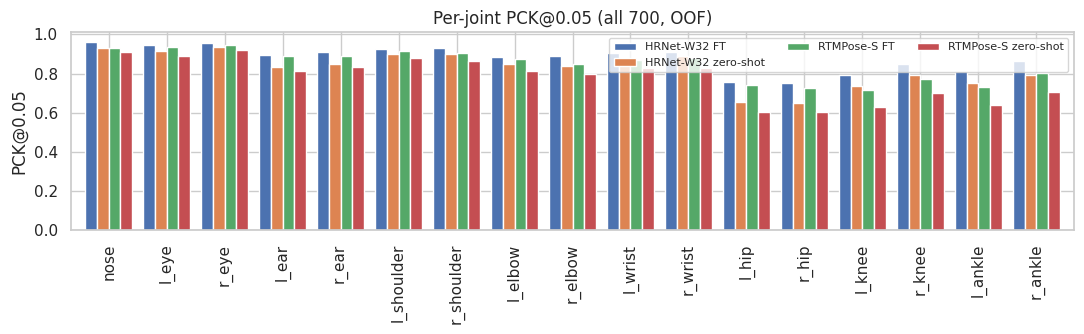

In [18]:
def coco_ap(kp, sc, idx):
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval
    import contextlib, io
    gt = dict(images=[REAL_RECS[i][0] for i in idx], annotations=[REAL_RECS[i][1] for i in idx],
              categories=COCO_CATEGORIES)
    with contextlib.redirect_stdout(io.StringIO()):
        cg = COCO(); cg.dataset = gt; cg.createIndex()
        dets = [dict(image_id=int(i), category_id=1, score=float(sc[i].mean()),
                     keypoints=np.c_[kp[i], sc[i]].reshape(-1).tolist()) for i in idx]
        cd = cg.loadRes(dets)
        E = COCOeval(cg, cd, "keypoints"); E.params.useSegm = None
        E.evaluate(); E.accumulate(); E.summarize()
    return E.stats[0], E.stats[1]          # AP, AP50

def pck(kp, idx, alpha=0.05, gt=None, boxes=None):
    gt = GT_KP if gt is None else gt
    out = []
    for n, i in enumerate(idx):
        b = META.bbox[i] if boxes is None else boxes[n]
        size = max(b[2], b[3]) if boxes is None else max(b[2] - b[0], b[3] - b[1])
        g = gt[i] if boxes is None else gt[n]
        d = np.linalg.norm((kp[i] if boxes is None else kp[n]) - g[:, :2], axis=1) / size
        out.append(np.where(g[:, 2] > 0, d <= alpha, np.nan))
    return np.array(out)                   # (n, 17) with NaN for unlabelled joints

SUBSETS = {"all 700 (OOF)": np.arange(N_IMG), "SyRIP test500": np.where(META.syrip_test500)[0],
           "SyRIP Test100": np.where(META.test100)[0]}
rows = []
for src, P in POSE2D.items():
    if src.startswith("GT"):
        continue
    for sname, idx in SUBSETS.items():
        ap, ap50 = coco_ap(P["kp"], P["sc"], idx)
        rows.append(dict(source=src, subset=sname, AP=ap, AP50=ap50,
                         **{"PCK@0.05": np.nanmean(pck(P["kp"], idx, 0.05)), "PCK@0.1": np.nanmean(pck(P["kp"], idx, 0.1))}))
POSE_METRICS = pd.DataFrame(rows)
print(POSE_METRICS.pivot(index="source", columns="subset", values=["AP", "PCK@0.05"]).round(3))
POSE_METRICS.to_csv(OUT / "pose_metrics.csv", index=False)

per_joint = pd.DataFrame({src: np.nanmean(pck(P["kp"], np.arange(N_IMG), 0.05), 0)
                          for src, P in POSE2D.items() if not src.startswith("GT")}, index=KP_NAMES)
fig, ax = plt.subplots(figsize=(11, 3.5))
per_joint.plot.bar(ax=ax, width=0.8); ax.set_ylabel("PCK@0.05"); ax.set_title("Per-joint PCK@0.05 (all 700, OOF)")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.savefig(FIG / "per_joint_pck.png", dpi=150); plt.show()
if "FiDIP (WACV'23)" in POSE2D:
    print("NOTE: FiDIP numbers on 'all 700' include its 200 training images; compare on 'SyRIP test500'.")

In [19]:
# --- flip consistency: || P(I) - unflip(P(flip(I))) || / bbox size, per joint (lower = more consistent)
if PRED_PKL:
    fc = {}
    for src, r in PRED_PKL.items():
        size = np.array([max(b[2], b[3]) for b in META.bbox])[:, None]
        e = np.linalg.norm(r["kp_raw"] - r["kp_flip"], axis=2) / size
        fc[src] = e.mean(0)
    FLIP_CONS = pd.DataFrame(fc, index=KP_NAMES)
    FLIP_CONS.loc["MEAN"] = FLIP_CONS.mean()
    print("Flip-consistency error (fraction of bbox size, flip-test OFF):\n", FLIP_CONS.round(4).T)
    FLIP_CONS.to_csv(OUT / "flip_consistency.csv")
    # does flip inconsistency predict pose error? (useful as a label-free reliability signal)
    for src, r in PRED_PKL.items():
        size = np.array([max(b[2], b[3]) for b in META.bbox])[:, None]
        fe = (np.linalg.norm(r["kp_raw"] - r["kp_flip"], axis=2) / size)[VIS]
        pe = (np.linalg.norm(r["kp"] - GT_KP[:, :, :2], axis=2) / size)[VIS]
        print(f"{src:28s} Spearman(flip error, pose error) = {spearmanr(fe, pe)[0]:.3f}")
else:
    print("no MMPose predictions yet (run sections 3-4)")

Flip-consistency error (fraction of bbox size, flip-test OFF):
                        nose   l_eye   r_eye   l_ear   r_ear  l_shoulder  r_shoulder  l_elbow  r_elbow  l_wrist  r_wrist   l_hip   r_hip  l_knee  r_knee  \
HRNet-W32 FT         0.0105  0.0108  0.0102  0.0132  0.0148      0.0149      0.0144   0.0203   0.0189   0.0207   0.0199  0.0239  0.0257  0.0335  0.0260   
HRNet-W32 zero-shot  0.0123  0.0118  0.0119  0.0167  0.0182      0.0166      0.0174   0.0255   0.0276   0.0253   0.0279  0.0336  0.0311  0.0494  0.0381   
RTMPose-S FT         0.0127  0.0120  0.0124  0.0163  0.0178      0.0156      0.0153   0.0218   0.0214   0.0255   0.0252  0.0240  0.0250  0.0387  0.0350   
RTMPose-S zero-shot  0.0144  0.0151  0.0150  0.0190  0.0189      0.0187      0.0185   0.0320   0.0292   0.0315   0.0346  0.0314  0.0322  0.0575  0.0531   

                     l_ankle  r_ankle    MEAN  
HRNet-W32 FT          0.0330   0.0248  0.0197  
HRNet-W32 zero-shot   0.0485   0.0367  0.0264  
RTMPose-S FT    

corruption           clean  occlude_limb   dark  bright   blur  noise  rotate15
source                                                                         
HRNet-W32 FT         0.885         0.796  0.866   0.729  0.875  0.824     0.903
HRNet-W32 zero-shot  0.829         0.749  0.809   0.691  0.816  0.796     0.834
RTMPose-S FT         0.848         0.757  0.822   0.652  0.825  0.722     0.846
RTMPose-S zero-shot  0.765         0.674  0.746   0.563  0.756  0.695     0.769

PCK@0.05 of the occluded joint itself:
 source          HRNet-W32 FT  HRNet-W32 zero-shot  RTMPose-S FT  RTMPose-S zero-shot
occluded joint                                                                      
l_ankle                 0.14                 0.00          0.21                 0.08
l_elbow                 0.36                 0.39          0.36                 0.17
l_knee                  0.20                 0.20          0.33                 0.10
l_wrist                 0.07                 0.00     

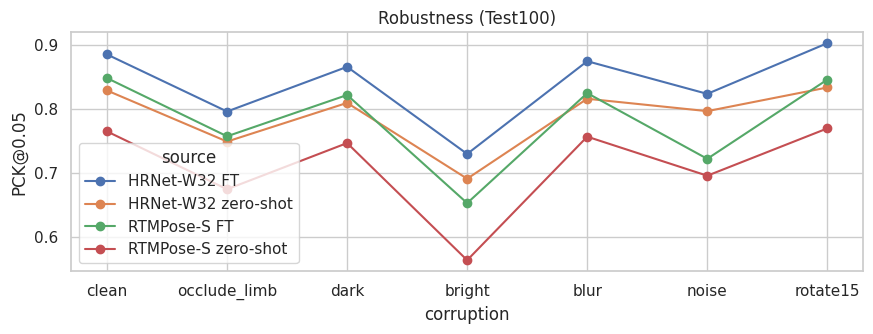

In [20]:
# --- robustness: PCK@0.05 under corruptions + which joints fail when a limb is occluded
if PRED_PKL:
    rob_rows, occl = [], defaultdict(list)
    for src, r in PRED_PKL.items():
        for c in CORRUPTIONS:
            d = r["rob"][c]
            if not d:
                continue
            ids = sorted(d)
            kp = np.stack([d[i]["kp"] for i in ids]); gt = np.stack([d[i]["gt"] for i in ids])
            boxes = np.stack([d[i]["box"] for i in ids])
            p = pck(kp, ids, 0.05, gt=gt, boxes=boxes)
            rob_rows.append(dict(source=src, corruption=c, PCK=np.nanmean(p)))
            if c == "occlude_limb":
                for n, i in enumerate(ids):
                    occl[src].append((d[i]["target"], p[n, d[i]["target"]]))
    ROBUST = pd.DataFrame(rob_rows).pivot(index="source", columns="corruption", values="PCK")[CORRUPTIONS]
    print(ROBUST.round(3))
    ROBUST.to_csv(OUT / "robustness_pck.csv")
    occ_df = pd.DataFrame([(s, KP_NAMES[t], ok) for s, v in occl.items() for t, ok in v],
                          columns=["source", "occluded joint", "hit"]).groupby(["occluded joint", "source"]).hit.mean().unstack()
    print("\nPCK@0.05 of the occluded joint itself:\n", occ_df.round(2))
    ax = ROBUST.T.plot(marker="o", figsize=(9, 3.5)); ax.set_ylabel("PCK@0.05"); ax.set_title("Robustness (Test100)")
    plt.tight_layout(); plt.savefig(FIG / "robustness.png", dpi=150); plt.show()

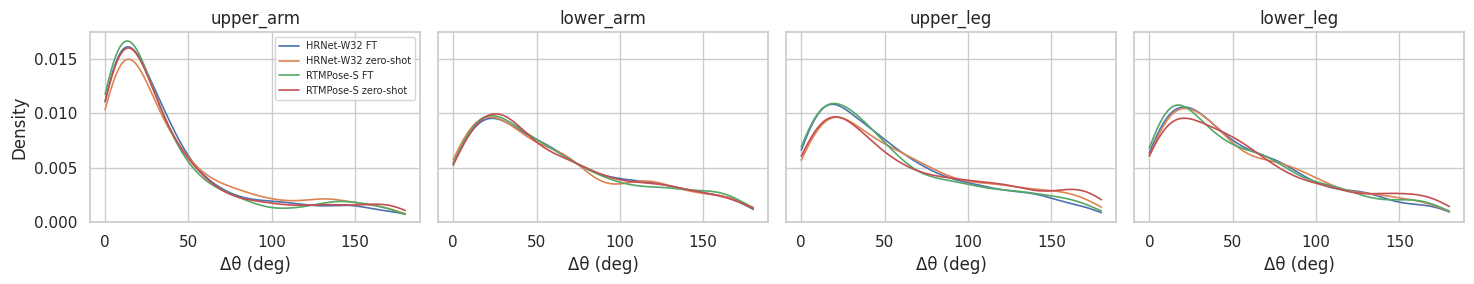

In [21]:
# 3D reference sources from the authors' repo (HW-HuP prediction and manually corrected "weak GT")
POSE3D = {}
if PATHS["p3d"] is not None and PATHS["p3d_names"] is not None and SURVEY_ORDER:
    names3d = np.array([Path(str(n)).name for n in np.load(PATHS["p3d_names"])])
    pos = {n: i for i, n in enumerate(names3d)}
    sel = np.array([pos[ORIG2SURVEY[n]] for n in ORIG_NAMES])
    POSE3D["HW-HuP 3D (WACV'23)"] = np.load(PATHS["p3d"])[sel]
    if PATHS["c3d"] is not None:
        POSE3D["Corrected 3D (oracle)"] = np.load(PATHS["c3d"])[sel]

assert POSE2D, "no 2D pose predictions available yet: run sections 3-4 (at least the zero-shot inference) first"
ANGLES = {s: limb_angles(P["kp"]) for s, P in POSE2D.items()}
ANGLES.update({s: limb_angles(P, LSP_IDX) for s, P in POSE3D.items()})


fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for l, ax in enumerate(axes):
    for s, A in ANGLES.items():
        sns.kdeplot(A[:, l], ax=ax, label=s, clip=(0, 180), lw=1.2)
    ax.set_title(LIMBS[l]); ax.set_xlabel("Δθ (deg)")
axes[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(FIG / "angle_distributions.png", dpi=150); plt.show()

                     AUC sym (3:1 split)  AUC angle≥30 (3:1 split)  opt. threshold (all data)  max κ
source                                                                                              
HRNet-W32 FT                       0.855                     0.859                       40.8  0.639
HRNet-W32 zero-shot                0.821                     0.828                       46.6  0.571
RTMPose-S FT                       0.840                     0.842                       41.6  0.595
RTMPose-S zero-shot                0.805                     0.817                       39.9  0.556


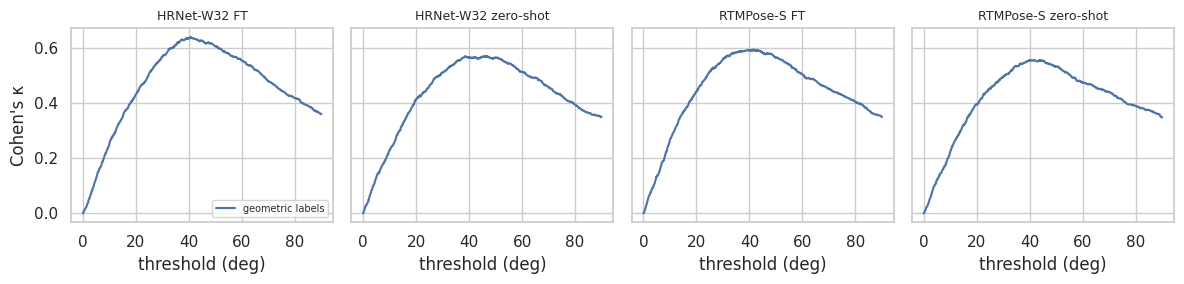

In [22]:
def kappa_bin_sweep(y, A, thresholds):
    """Cohen's kappa of (A < t) vs binary y for many thresholds at once."""
    P = A[None, :] < thresholds[:, None]
    po = (P == y[None].astype(bool)).mean(1)
    py, pp = y.mean(), P.mean(1)
    pe = py * pp + (1 - py) * (1 - pp)
    return (po - pe) / (1 - pe + 1e-12)

from sklearn.model_selection import train_test_split
THR_GRID = np.arange(0, 90.01, 0.1)
y_sym, y_ang = BAYES_SYM, BAYES_ANG
rows = []
for s, A in ANGLES.items():
    a = A.reshape(-1)
    tr, te = train_test_split(np.arange(len(a)), test_size=0.25, random_state=SEED)
    lr_sym = LogisticRegression().fit(a[tr, None], y_sym[tr])
    lr_ang = LogisticRegression().fit(a[tr, None], (y_ang[tr] > 0).astype(int))
    k = kappa_bin_sweep(y_sym, a, THR_GRID)
    rows.append(dict(source=s,
                     **{"AUC sym (3:1 split)": roc_auc_score(y_sym[te], lr_sym.predict_proba(a[te, None])[:, 1]),
                        "AUC angle≥30 (3:1 split)": roc_auc_score((y_ang[te] > 0), lr_ang.predict_proba(a[te, None])[:, 1]),
                        "opt. threshold (all data)": THR_GRID[k.argmax()], "max κ": k.max()}))
PAPER_T2 = pd.DataFrame(rows).set_index("source")
print(PAPER_T2.round(3))
if HAVE_SURVEY:
    print("paper Table 2: AUC 2D GT .62 | FiDIP .61 | DarkPose .60 | corrected 3D .73 | HW-HuP .68 | SPIN .60;"
          " thresholds 39.1 / 42.0 / 43.7 / 27.7 / 27.9 / 17.8")

fig, axes = plt.subplots(1, len(ANGLES), figsize=(3 * len(ANGLES), 3), sharey=True)
for ax, (s, A) in zip(np.atleast_1d(axes), ANGLES.items()):
    a = A.reshape(-1)
    if HAVE_SURVEY:
        ax.plot(THR_GRID, kappa_bin_sweep(VOTE_SYM, a, THR_GRID), label="human vote")
        ax.plot(THR_GRID, np.mean([kappa_bin_sweep(SYM[:, r], a, THR_GRID) for r in range(10)], 0), label="mean over raters")
    ax.plot(THR_GRID, kappa_bin_sweep(BAYES_SYM, a, THR_GRID), label=f"{LABEL_MODE} labels")
    ax.set_title(s, fontsize=9); ax.set_xlabel("threshold (deg)")
np.atleast_1d(axes)[0].set_ylabel("Cohen's κ"); np.atleast_1d(axes)[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "threshold_sweep.png", dpi=150); plt.show()

In [23]:
# ---------- common evaluation helpers (used for every assessor in the ablation) ----------
GROUP_CODES = pd.factorize(META.group)[0]

def metrics(score_sym, pred_sym, pred_ang, rows_mask=None):
    m = np.ones(len(y_sym), bool) if rows_mask is None else rows_mask
    return {"AUROC sym": roc_auc_score(y_sym[m], score_sym[m]),
            "κ sym": cohen_kappa_score(y_sym[m], pred_sym[m]),
            "κw angle (3-cls)": cohen_kappa_score(y_ang[m], pred_ang[m], weights="quadratic"),
            "macro-F1 angle": f1_score(y_ang[m], pred_ang[m], average="macro")}

def cluster_bootstrap_auc(score, n_boot=1000, rows_mask=None, rng_seed=SEED):
    """95% CI of AUROC resampling source-video clusters (the right unit of independence here)."""
    rng = np.random.default_rng(rng_seed)
    m = np.ones(len(y_sym), bool) if rows_mask is None else rows_mask
    g_rows = GROUP_CODES[ROW_IMG]
    groups = np.unique(g_rows[m])
    members = {g: np.where((g_rows == g) & m)[0] for g in groups}
    out = []
    for _ in range(n_boot):
        idx = np.concatenate([members[g] for g in rng.choice(groups, len(groups))])
        if y_sym[idx].min() != y_sym[idx].max():
            out.append(roc_auc_score(y_sym[idx], score[idx]))
    return np.percentile(out, [2.5, 97.5])

RESULTS = {}   # (pose source, assessor) -> dict(score_sym, pred_sym, pred_ang)

def fold_threshold_baseline(A):
    a = A.reshape(-1)
    pred = np.zeros_like(y_sym)
    for k in range(N_FOLDS):
        tr, te = ROW_FOLD != k, ROW_FOLD == k
        t = THR_GRID[kappa_bin_sweep(y_sym[tr], a[tr], THR_GRID).argmax()]
        pred[te] = (a[te] < t).astype(int)
    return dict(score_sym=-a, pred_sym=pred, pred_ang=angle_class(a))

for s, A in ANGLES.items():
    RESULTS[(s, "angle threshold")] = fold_threshold_baseline(A)
print("threshold baselines:", len(RESULTS))

threshold baselines: 4


In [24]:
def segment_conf(sc):
    """(N,17) -> (N,4,2): mean confidence of left/right segment joints per limb pair."""
    out = np.zeros((len(sc), 4, 2))
    for l, (a, b, c, d) in enumerate(LIMB_JOINTS.values()):
        out[:, l, 0] = (sc[:, a] + sc[:, b]) / 2
        out[:, l, 1] = (sc[:, c] + sc[:, d]) / 2
    return out

CONF_ROWS = []
for s, P in POSE2D.items():
    if s.startswith("GT"):
        continue
    A = ANGLES[s]; W = segment_conf(P["sc"]); w = np.clip(W[..., 0] * W[..., 1], 0, None)
    S_w = (w * A).reshape(-1)
    wmin = W.min(-1).reshape(-1); a = A.reshape(-1)
    med = np.repeat(np.median(A, 1), 4)
    # gated: tune tau on training folds by AUROC, apply to test fold
    score_g = np.zeros_like(a)
    taus = np.quantile(wmin, np.linspace(0, 0.5, 11))
    for k in range(N_FOLDS):
        tr, te = ROW_FOLD != k, ROW_FOLD == k
        best = max(taus, key=lambda t: roc_auc_score(y_sym[tr], -np.where(wmin[tr] < t, med[tr], a[tr])))
        score_g[te] = -np.where(wmin[te] < best, med[te], a[te])
    RESULTS[(s, "conf-weighted angle")] = fold_threshold_baseline(S_w.reshape(-1, 4))
    CONF_ROWS.append({"source": s, "Δθ": roc_auc_score(y_sym, -a), "w_L·w_R·Δθ": roc_auc_score(y_sym, -S_w),
                      "gated Δθ": roc_auc_score(y_sym, score_g),
                      "corr(conf, |pose err|)": spearmanr(
                          P["sc"][VIS], -np.linalg.norm(P["kp"] - GT_KP[:, :, :2], axis=2)[VIS])[0]})
CONF_TABLE = pd.DataFrame(CONF_ROWS).set_index("source")
print(f"AUROC (symmetric vs {LABEL_MODE} labels) of different symmetry scores:\n", CONF_TABLE.round(3))
print("A confidence weighting can only help if confidence actually tracks keypoint error (last column).")

AUROC (symmetric vs geometric labels) of different symmetry scores:
                         Δθ  w_L·w_R·Δθ  gated Δθ  corr(conf, |pose err|)
source                                                                  
HRNet-W32 FT         0.869       0.844     0.866                   0.557
HRNet-W32 zero-shot  0.840       0.804     0.844                   0.621
RTMPose-S FT         0.855       0.798     0.853                   0.608
RTMPose-S zero-shot  0.824       0.757     0.833                   0.653
A confidence weighting can only help if confidence actually tracks keypoint error (last column).


In [25]:
def canonicalize(kp):
    """kp (N,17,2) -> canonical coords (N,17,2), torso angle (N,), scale (N,)."""
    sh = (kp[:, 5] + kp[:, 6]) / 2; hp = (kp[:, 11] + kp[:, 12]) / 2
    c = (sh + hp) / 2; t = sh - hp
    s = np.linalg.norm(t, axis=1)
    span = np.linalg.norm(kp.max(1) - kp.min(1), axis=1)
    s = np.where(s < 0.05 * span, span / 3, s) + 1e-6
    th = np.arctan2(t[:, 0], -t[:, 1])                      # angle of torso vs image "up"
    R = np.stack([np.stack([np.cos(th), np.sin(th)], 1), np.stack([-np.sin(th), np.cos(th)], 1)], 1)  # rotate by -th
    X = np.einsum("nij,nkj->nki", R, kp - c[:, None]) / s[:, None, None]
    return X, th, s

def geo_features(kp, sc):
    """Image-level geometric features + per-limb features. Returns (img_feats (N,F), limb_feats (N,4,3))."""
    X, th, s = canonicalize(kp)
    A = limb_angles(kp)
    seglen = lambda a, b: np.linalg.norm(kp[:, a] - kp[:, b], axis=1) + 1e-6
    ratio = np.stack([np.log(seglen(a, b) / seglen(c, d)) for a, b, c, d in LIMB_JOINTS.values()], 1)
    W = segment_conf(sc).min(-1)
    twist = _angle(kp[:, 5] - kp[:, 6], kp[:, 11] - kp[:, 12])
    widths = np.stack([seglen(5, 6), seglen(11, 12)], 1) / s[:, None]
    img = np.c_[A / 90, ratio, twist / 90, np.sin(th), np.cos(th), widths, X.reshape(len(X), -1), sc]
    limb = np.stack([A / 90, ratio, W], -1)
    return img, limb

def row_features(kp, sc):
    img, limb = geo_features(kp, sc)
    onehot = np.tile(np.eye(4), (len(kp), 1))
    return np.c_[onehot, limb.reshape(-1, 3), np.repeat(img, 4, axis=0)]

def cv_sklearn(make_model, Xr):
    score = np.zeros(len(y_sym)); pred_s = np.zeros(len(y_sym), int); pred_a = np.zeros(len(y_sym), int)
    for k in range(N_FOLDS):
        tr, te = ROW_FOLD != k, ROW_FOLD == k
        ms = make_model("bin").fit(Xr[tr], y_sym[tr])
        ma = make_model("multi").fit(Xr[tr], y_ang[tr])
        score[te] = ms.predict_proba(Xr[te])[:, 1]
        pred_s[te] = (score[te] > 0.5).astype(int)
        pred_a[te] = ma.predict_proba(Xr[te]).argmax(1)
    return dict(score_sym=score, pred_sym=pred_s, pred_ang=pred_a)

def make_logreg(kind):
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000, class_weight="balanced"))

def make_mlp_seeded(seed):
    def f(kind):
        return make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-2,
                                                             learning_rate_init=1e-3, max_iter=600, random_state=seed))
    return f

# --- results cache on scratch: a kernel/session reset no longer loses trained classifiers.
# Keys are (pose source, assessor); new pose sources (e.g. fine-tuned models) are computed, old ones reloaded.
import pickle
CACHE_F = OUT / f"results_cache_{LABEL_MODE}_{N_FOLDS}fold.pkl"
CLEAR_CACHE = False                            # set True after changing labels, features or model code
RESULT_CACHE = {} if (CLEAR_CACHE or not CACHE_F.exists()) else pickle.load(open(CACHE_F, "rb"))
print(f"results cache: {len(RESULT_CACHE)} entries in {CACHE_F}")

def cached(key, fn):
    if key not in RESULT_CACHE:
        RESULT_CACHE[key] = fn()
        tmp = CACHE_F.with_suffix(".tmp")
        pickle.dump(RESULT_CACHE, open(tmp, "wb")); tmp.replace(CACHE_F)   # atomic write
    return RESULT_CACHE[key]

CLS_SOURCES = [s for s in POSE2D]          # run learned assessors on every 2D source (restrict here if slow)
for s in CLS_SOURCES:
    Xr = row_features(POSE2D[s]["kp"], POSE2D[s]["sc"])
    RESULTS[(s, "LogReg (geo)")] = cached((s, "LogReg (geo)"), lambda: cv_sklearn(make_logreg, Xr))
    def _mlp():
        runs = [cv_sklearn(make_mlp_seeded(sd), Xr) for sd in CLS_SEEDS]
        sc_ = np.mean([r["score_sym"] for r in runs], 0)
        return dict(score_sym=sc_, pred_sym=(sc_ > 0.5).astype(int),
                    pred_ang=np.round(np.mean([r["pred_ang"] for r in runs], 0)).astype(int))
    RESULTS[(s, "MLP (geo)")] = cached((s, "MLP (geo)"), _mlp)
    print(f"{s:28s} LogReg AUROC {roc_auc_score(y_sym, RESULTS[(s, 'LogReg (geo)')]['score_sym']):.3f} | "
          f"MLP AUROC {roc_auc_score(y_sym, RESULTS[(s, 'MLP (geo)')]['score_sym']):.3f}")

results cache: 22 entries in /home/dpraju90/scratch/infant_symmetry/outputs/results_cache_geometric_5fold.pkl
HRNet-W32 FT                 LogReg AUROC 0.877 | MLP AUROC 0.843
HRNet-W32 zero-shot          LogReg AUROC 0.844 | MLP AUROC 0.837
RTMPose-S FT                 LogReg AUROC 0.862 | MLP AUROC 0.842
RTMPose-S zero-shot          LogReg AUROC 0.830 | MLP AUROC 0.812


In [26]:
if HAVE_TORCH:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F

    def build_adj(mirror=True):
        A = np.eye(17, dtype=bool)
        for a, b in SKELETON + (MIRROR_EDGES if mirror else []):
            A[a, b] = A[b, a] = True
        return torch.tensor(A)

    class DenseGAT(nn.Module):
        def __init__(self, d_in, d_out, heads=4, drop=0.1):
            super().__init__()
            self.h, self.d = heads, d_out // heads
            self.W = nn.Linear(d_in, d_out, bias=False)
            self.a_src = nn.Parameter(torch.randn(heads, self.d) * 0.1)
            self.a_dst = nn.Parameter(torch.randn(heads, self.d) * 0.1)
            self.drop = nn.Dropout(drop)
        def forward(self, x, adj):
            B, N, _ = x.shape
            Wh = self.W(x).view(B, N, self.h, self.d)
            e = (Wh * self.a_dst).sum(-1)[:, :, None, :] + (Wh * self.a_src).sum(-1)[:, None, :, :]   # (B,i,j,H)
            e = F.leaky_relu(e, 0.2).masked_fill(~adj[None, :, :, None], float("-inf"))
            att = self.drop(torch.softmax(e, dim=2))
            self.last_att = att.detach()
            return torch.einsum("bijh,bjhd->bihd", att, Wh).reshape(B, N, -1)

    class DenseGCN(nn.Module):
        def __init__(self, d_in, d_out, **_):
            super().__init__()
            self.W = nn.Linear(d_in, d_out)
        def forward(self, x, adj):
            A = adj.float(); d = A.sum(1).rsqrt()
            return (d[:, None] * A * d[None, :]) @ self.W(x)

    class SymmetryGNN(nn.Module):
        def __init__(self, layer="gat", hidden=64, n_layers=3, use_geo=False, drop=0.1, mirror=True):
            super().__init__()
            self.register_buffer("adj", build_adj(mirror))
            self.joint_emb = nn.Embedding(17, 16)
            self.inp = nn.Linear(3 + 16, hidden)
            L = DenseGAT if layer == "gat" else DenseGCN
            self.layers = nn.ModuleList([L(hidden, hidden, heads=4, drop=drop) for _ in range(n_layers)])
            self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(n_layers)])
            self.limb_emb = nn.Embedding(4, 16)
            self.use_geo = use_geo
            self.register_buffer("limb_idx", torch.tensor(list(LIMB_JOINTS.values())))
            d_read = hidden * 7 + 16 + (3 if use_geo else 0)
            self.head = nn.Sequential(nn.Linear(d_read, 128), nn.GELU(), nn.Dropout(drop), nn.Linear(128, 1 + 3))
        def forward(self, x, geo=None):
            B = x.shape[0]
            h = self.inp(torch.cat([x, self.joint_emb.weight[None].expand(B, -1, -1)], -1))
            for layer, norm in zip(self.layers, self.norms):
                h = norm(h + F.elu(layer(h, self.adj)))
            hl = h[:, self.limb_idx]                                  # (B,4,4,H)  [Lp, Ld, Rp, Rd]
            z = [hl[:, :, 0], hl[:, :, 1], hl[:, :, 2], hl[:, :, 3],
                 (hl[:, :, 0] - hl[:, :, 2]).abs(), (hl[:, :, 1] - hl[:, :, 3]).abs(),
                 h.mean(1, keepdim=True).expand(-1, 4, -1),
                 self.limb_emb.weight[None].expand(B, -1, -1)]
            if self.use_geo:
                z.append(geo)
            out = self.head(torch.cat(z, -1))                         # (B,4,4)
            return out[..., 0], out[..., 1:]                          # sym logit (B,4), angle logits (B,4,3)

    FLIP_T = torch.tensor(FLIP_PERM)

    def flip_batch(x, geo):
        x = x[:, FLIP_T].clone(); x[..., 0] = -x[..., 0]
        geo = geo.clone(); geo[..., 1] = -geo[..., 1]               # log length ratio L/R changes sign
        return x, geo

    def augment(x, geo, gen):
        B = x.shape[0]
        flip = torch.rand(B, generator=gen) < 0.5
        xf, gf = flip_batch(x, geo)
        x = torch.where(flip[:, None, None], xf, x); geo = torch.where(flip[:, None, None], gf, geo)
        th = (torch.rand(B, generator=gen) - 0.5) * math.radians(30)
        R = torch.stack([torch.stack([th.cos(), -th.sin()], 1), torch.stack([th.sin(), th.cos()], 1)], 1)
        xy = torch.einsum("bij,bnj->bni", R, x[..., :2]) * (0.9 + 0.2 * torch.rand(B, 1, 1, generator=gen))
        xy = xy + torch.randn(xy.shape, generator=gen) * 0.03 * (1.5 - x[..., 2:3].clamp(0, 1))
        drop = (torch.rand(B, 17, 1, generator=gen) < 0.05).float()
        x = torch.cat([xy * (1 - drop), x[..., 2:3] * (1 - drop)], -1)
        return x, geo

    def make_graph_inputs(kp, sc):
        X, _, _ = canonicalize(kp)
        _, limb = geo_features(kp, sc)
        x = np.concatenate([X, sc[..., None]], -1)
        return torch.tensor(x, dtype=torch.float32), torch.tensor(limb, dtype=torch.float32)

    def train_gnn(x, geo, ys, ya, tr_img, layer, use_geo, seed, epochs=150, lam_flip=0.5, bs=64, mirror=True):
        torch.manual_seed(seed); gen = torch.Generator().manual_seed(seed)
        model = SymmetryGNN(layer, use_geo=use_geo, mirror=mirror).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-3)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=epochs * math.ceil(len(tr_img) / bs))
        tr_img = np.asarray(tr_img)
        ys_t, ya_t = torch.tensor(ys, dtype=torch.float32), torch.tensor(ya, dtype=torch.long)
        pos = float(ys[tr_img].mean())
        pos_w = torch.tensor((1 - pos) / pos, dtype=torch.float32, device=DEVICE)
        counts = np.bincount(ya[tr_img].reshape(-1), minlength=3)
        cw = torch.tensor(counts.sum() / (3 * counts + 1), dtype=torch.float32, device=DEVICE)
        for ep in range(epochs):
            model.train()
            perm = torch.as_tensor(tr_img)[torch.randperm(len(tr_img), generator=gen)]
            for b in perm.split(bs):
                xb, gb = augment(x[b], geo[b], gen)
                xb, gb, yb, ab = xb.to(DEVICE), gb.to(DEVICE), ys_t[b].to(DEVICE), ya_t[b].to(DEVICE)
                s_logit, a_logit = model(xb, gb)
                loss = F.binary_cross_entropy_with_logits(s_logit, yb, pos_weight=pos_w) + \
                       F.cross_entropy(a_logit.reshape(-1, 3), ab.reshape(-1), weight=cw)
                if lam_flip > 0:
                    xf, gf = flip_batch(xb.cpu(), gb.cpu())
                    s_f, a_f = model(xf.to(DEVICE), gf.to(DEVICE))
                    loss = loss + lam_flip * (F.mse_loss(torch.sigmoid(s_logit), torch.sigmoid(s_f)) +
                                              F.mse_loss(a_logit.softmax(-1), a_f.softmax(-1)))
                opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        return model

    @torch.no_grad()
    def predict_gnn(model, x, geo, idx):
        model.eval()
        idx = torch.as_tensor(np.asarray(idx))
        xb, gb = x[idx].to(DEVICE), geo[idx].to(DEVICE)
        s1, a1 = model(xb, gb)
        xf, gf = flip_batch(xb.cpu(), gb.cpu())
        s2, a2 = model(xf.to(DEVICE), gf.to(DEVICE))                 # flip test-time averaging
        return ((torch.sigmoid(s1) + torch.sigmoid(s2)) / 2).cpu().numpy(), ((a1.softmax(-1) + a2.softmax(-1)) / 2).cpu().numpy()

    def cv_gnn(src, layer, use_geo, lam_flip=0.5, mirror=True, epochs=150):
        x, geo = make_graph_inputs(POSE2D[src]["kp"], POSE2D[src]["sc"])
        ys, ya = y_sym.reshape(N_IMG, 4), y_ang.reshape(N_IMG, 4)
        ps, pa = np.zeros((N_IMG, 4)), np.zeros((N_IMG, 4, 3))
        for k in range(N_FOLDS):
            tr, te = np.where(FOLD != k)[0], np.where(FOLD == k)[0]
            for sd in CLS_SEEDS:
                m = train_gnn(x, geo, ys, ya, tr, layer, use_geo, seed=sd, lam_flip=lam_flip, mirror=mirror, epochs=epochs)
                s_, a_ = predict_gnn(m, x, geo, te)
                ps[te] += s_ / len(CLS_SEEDS); pa[te] += a_ / len(CLS_SEEDS)
        ps, pa = ps.reshape(-1), pa.reshape(-1, 3)
        return dict(score_sym=ps, pred_sym=(ps > 0.5).astype(int), pred_ang=pa.argmax(1))

    GNN_VARIANTS = {"GCN": dict(layer="gcn", use_geo=False), "GAT": dict(layer="gat", use_geo=False),
                    "GAT + geo": dict(layer="gat", use_geo=True)}
    print(f"training {len(CLS_SOURCES) * len(GNN_VARIANTS) * N_FOLDS * len(CLS_SEEDS)} small GNNs "
          f"(~10-20 s each on CPU, faster on GPU); trim CLS_SOURCES / CLS_SEEDS to go quicker")
    for s in CLS_SOURCES:
        for name, kw in GNN_VARIANTS.items():
            t0 = time.time()
            RESULTS[(s, name)] = cached((s, name), lambda: cv_gnn(s, **kw))
            print(f"{s:28s} {name:10s} AUROC {roc_auc_score(y_sym, RESULTS[(s, name)]['score_sym']):.3f} "
                  f"({time.time()-t0:.0f}s)")
else:
    print("PyTorch not available in this kernel: GNN section skipped")

training 180 small GNNs (~10-20 s each on CPU, faster on GPU); trim CLS_SOURCES / CLS_SEEDS to go quicker
HRNet-W32 FT                 GCN        AUROC 0.810 (0s)
HRNet-W32 FT                 GAT        AUROC 0.815 (0s)
HRNet-W32 FT                 GAT + geo  AUROC 0.894 (0s)
HRNet-W32 zero-shot          GCN        AUROC 0.813 (0s)
HRNet-W32 zero-shot          GAT        AUROC 0.817 (0s)
HRNet-W32 zero-shot          GAT + geo  AUROC 0.876 (0s)
RTMPose-S FT                 GCN        AUROC 0.799 (0s)
RTMPose-S FT                 GAT        AUROC 0.804 (0s)
RTMPose-S FT                 GAT + geo  AUROC 0.880 (0s)
RTMPose-S zero-shot          GCN        AUROC 0.804 (0s)
RTMPose-S zero-shot          GAT        AUROC 0.809 (0s)
RTMPose-S zero-shot          GAT + geo  AUROC 0.859 (0s)


In [27]:
# --- GAT ablations on the best pose source: mirror edges, flip-consistency loss
if HAVE_TORCH:
    # ablate on the deployable pose source where GAT + geo works best (prefers fine-tuned models once they exist)
    cands = [s for s in POSE2D if not s.startswith("GT") and (s, "GAT + geo") in RESULTS]
    ft = [s for s in cands if "FT" in s]
    ABL_SRC = max(ft or cands, key=lambda s: roc_auc_score(y_sym, RESULTS[(s, "GAT + geo")]["score_sym"]))
    abl = {"GAT + geo (full)": RESULTS[(ABL_SRC, "GAT + geo")],
           "− mirror edges": cached((ABL_SRC, "abl: no mirror edges"), lambda: cv_gnn(ABL_SRC, "gat", True, mirror=False)),
           "− flip-consistency loss": cached((ABL_SRC, "abl: no flip loss"), lambda: cv_gnn(ABL_SRC, "gat", True, lam_flip=0.0)),
           "− geo features (plain GAT)": RESULTS[(ABL_SRC, "GAT")]}
    ABLATION = pd.DataFrame({k: metrics(**v) for k, v in abl.items()}).T
    print(f"GAT ablations on {ABL_SRC}:\n", ABLATION.round(3))
    ABLATION.to_csv(OUT / "gat_ablation.csv")

GAT ablations on HRNet-W32 FT:
                             AUROC sym  κ sym  κw angle (3-cls)  macro-F1 angle
GAT + geo (full)                0.894  0.609             0.688           0.641
− mirror edges                  0.894  0.614             0.684           0.643
− flip-consistency loss         0.893  0.604             0.691           0.643
− geo features (plain GAT)      0.815  0.489             0.529           0.541


                                         AUROC sym  κ sym  κw angle (3-cls)  macro-F1 angle    AUROC 95% CI
pose                assessor                                                                               
HRNet-W32 FT        GAT + geo                0.894  0.609             0.688           0.641  [0.879, 0.907]
RTMPose-S FT        GAT + geo                0.880  0.595             0.656           0.629  [0.863, 0.895]
HRNet-W32 FT        LogReg (geo)             0.877  0.592             0.661           0.615  [0.860, 0.892]
HRNet-W32 zero-shot GAT + geo                0.876  0.606             0.653           0.624  [0.857, 0.891]
HRNet-W32 FT        angle threshold          0.869  0.634             0.690           0.654  [0.849, 0.887]
RTMPose-S FT        LogReg (geo)             0.862  0.561             0.637           0.600  [0.843, 0.878]
RTMPose-S zero-shot GAT + geo                0.859  0.555             0.615           0.600  [0.840, 0.876]
RTMPose-S FT        angle th

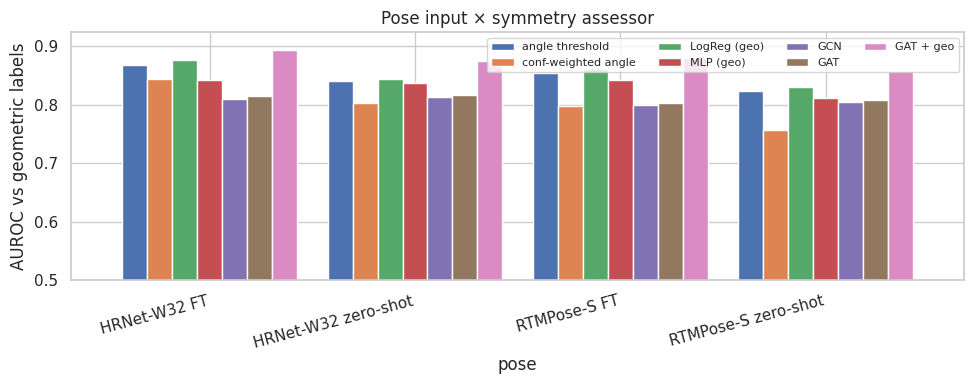

In [28]:
res_rows = []
for (src, method), r in RESULTS.items():
    for subset, mask in [("all 700", None), ("SyRIP test500", np.repeat(META.syrip_test500.values, 4))]:
        row = dict(pose=src, assessor=method, subset=subset, **metrics(r["score_sym"], r["pred_sym"], r["pred_ang"], mask))
        lo, hi = cluster_bootstrap_auc(r["score_sym"], n_boot=500, rows_mask=mask)
        row["AUROC 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
        res_rows.append(row)
RES = pd.DataFrame(res_rows)
RES.to_csv(OUT / "symmetry_results_full.csv", index=False)
main = RES[RES.subset == "all 700"].drop(columns="subset").set_index(["pose", "assessor"]).sort_values("AUROC sym", ascending=False)
print(main.round(3).to_string())

# compact ablation table in the format of the proposal
order = ["angle threshold", "conf-weighted angle", "LogReg (geo)", "MLP (geo)", "GCN", "GAT", "GAT + geo"]
piv = RES[RES.subset == "all 700"].pivot(index="pose", columns="assessor", values="AUROC sym")
piv = piv[[c for c in order if c in piv.columns]]
print("\nAUROC (symmetric) — rows: pose input, columns: symmetry assessor\n", piv.round(3))
for s, A in ANGLES.items():
    if s in POSE3D:
        print(f"  3D reference [{s}] angle threshold AUROC: {roc_auc_score(y_sym, -A.reshape(-1)):.3f}")

fig, ax = plt.subplots(figsize=(10, 4))
piv.plot.bar(ax=ax, width=0.85); ax.set_ylim(0.5, max(0.85, np.nanmax(piv.values) + 0.03))
ax.set_ylabel(f"AUROC vs {LABEL_MODE} labels"); ax.legend(fontsize=8, ncol=4); ax.set_title("Pose input × symmetry assessor")
plt.xticks(rotation=15, ha="right"); plt.tight_layout(); plt.savefig(FIG / "main_ablation.png", dpi=150); plt.show()

In [29]:
# --- paired cluster-bootstrap test: best learned assessor vs the WACV baseline (FiDIP + angle threshold)
def paired_boot(a, b, n_boot=2000, mask=None):
    rng = np.random.default_rng(SEED)
    m = np.ones(len(y_sym), bool) if mask is None else mask
    g_rows = GROUP_CODES[ROW_IMG]; groups = np.unique(g_rows[m])
    members = {g: np.where((g_rows == g) & m)[0] for g in groups}
    d = []
    for _ in range(n_boot):
        idx = np.concatenate([members[g] for g in rng.choice(groups, len(groups))])
        if y_sym[idx].min() != y_sym[idx].max():
            d.append(roc_auc_score(y_sym[idx], a[idx]) - roc_auc_score(y_sym[idx], b[idx]))
    d = np.array(d)
    return d.mean(), np.percentile(d, [2.5, 97.5]), (d <= 0).mean()

BASE = (BASE_SRC, "angle threshold")
if BASE in RESULTS:
    cand = [k for k in RESULTS if k[0] in POSE2D and not k[0].startswith("GT")]   # deployable 2D pipelines only
    best = max(cand, key=lambda k: roc_auc_score(y_sym, RESULTS[k]["score_sym"]))
    for subset, mask in [("all 700", None), ("SyRIP test500", np.repeat(META.syrip_test500.values, 4))]:
        md, ci, p = paired_boot(RESULTS[best]["score_sym"], RESULTS[BASE]["score_sym"], mask=mask)
        print(f"[{subset}] {best} − {BASE}: ΔAUROC = {md:+.3f}, 95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}], one-sided p ≈ {p:.3f}")
    BEST = best

[all 700] ('HRNet-W32 FT', 'GAT + geo') − ('HRNet-W32 zero-shot', 'angle threshold'): ΔAUROC = +0.054, 95% CI [+0.043, +0.068], one-sided p ≈ 0.000
[SyRIP test500] ('HRNet-W32 FT', 'GAT + geo') − ('HRNet-W32 zero-shot', 'angle threshold'): ΔAUROC = +0.053, 95% CI [+0.039, +0.068], one-sided p ≈ 0.000


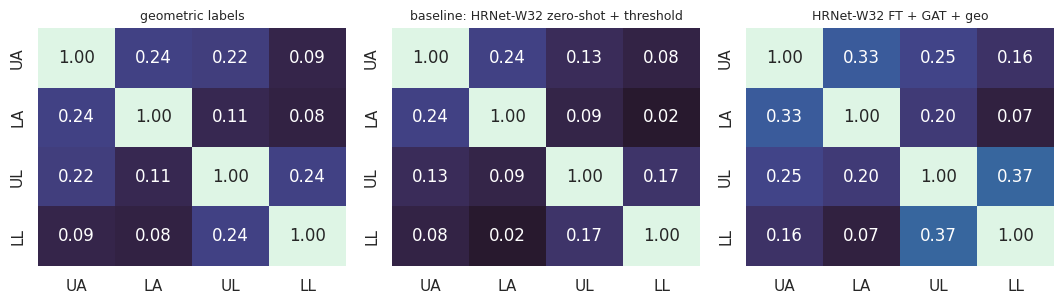

mean arm↔leg κ (lower = less cross-limb bias): {'geometric labels': 0.126, 'baseline: HRNet-W32 zero-shot + threshold': 0.083, 'HRNet-W32 FT + GAT + geo': 0.171}

Internal consistency: Spearman(angle class, asymmetry)
 geometric labels                         0.88
HRNet-W32 FT | angle threshold           0.88
HRNet-W32 zero-shot | angle threshold    0.88
RTMPose-S FT | angle threshold           0.88
RTMPose-S zero-shot | angle threshold    0.88
HRNet-W32 FT | MLP (geo)                 0.72
HRNet-W32 zero-shot | MLP (geo)          0.73
RTMPose-S FT | MLP (geo)                 0.73
RTMPose-S zero-shot | MLP (geo)          0.70
HRNet-W32 FT | GAT + geo                 0.86
HRNet-W32 zero-shot | GAT + geo          0.86
RTMPose-S FT | GAT + geo                 0.85
RTMPose-S zero-shot | GAT + geo          0.86


In [30]:
def interlimb_kappa(labels_2800):
    L = labels_2800.reshape(N_IMG, 4)
    return np.array([[cohen_kappa_score(L[:, i], L[:, j]) for j in range(4)] for i in range(4)])

panels = {}
if HAVE_SURVEY:
    panels["Human raters (mean)"] = np.mean([interlimb_kappa(SYM[:, r].astype(int)) for r in range(10)], 0)
panels[f"{LABEL_MODE} labels"] = interlimb_kappa(BAYES_SYM)
if BASE in RESULTS:
    panels[f"baseline: {BASE[0]} + threshold"] = interlimb_kappa(RESULTS[BASE]["pred_sym"])
if "BEST" in globals():
    panels[f"{BEST[0]} + {BEST[1]}"] = interlimb_kappa(RESULTS[BEST]["pred_sym"])
fig, axes = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 3.2))
for ax, (t, M) in zip(axes, panels.items()):
    sns.heatmap(M, vmin=-0.1, vmax=1, annot=True, fmt=".2f", cmap="mako", cbar=False, ax=ax,
                xticklabels=["UA", "LA", "UL", "LL"], yticklabels=["UA", "LA", "UL", "LL"])
    ax.set_title(t, fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "interlimb_kappa.png", dpi=150); plt.show()
arm_leg = {t: float(M[:2, 2:].mean()) for t, M in panels.items()}
print("mean arm↔leg κ (lower = less cross-limb bias):", {k: round(v, 3) for k, v in arm_leg.items()})

cons = {f"Rater {r+1}": spearmanr(ANG[:, r], 1 - SYM[:, r])[0] for r in range(10)} if HAVE_SURVEY else {}
cons[f"{LABEL_MODE} labels"] = spearmanr(BAYES_ANG, 1 - BAYES_SYM)[0]
for k, r in RESULTS.items():
    if k[1] in ("angle threshold", "GAT + geo", "MLP (geo)"):
        cons[f"{k[0]} | {k[1]}"] = spearmanr(r["pred_ang"], 1 - r["pred_sym"])[0]
print("\nInternal consistency: Spearman(angle class, asymmetry)\n", pd.Series(cons).round(2).to_string())

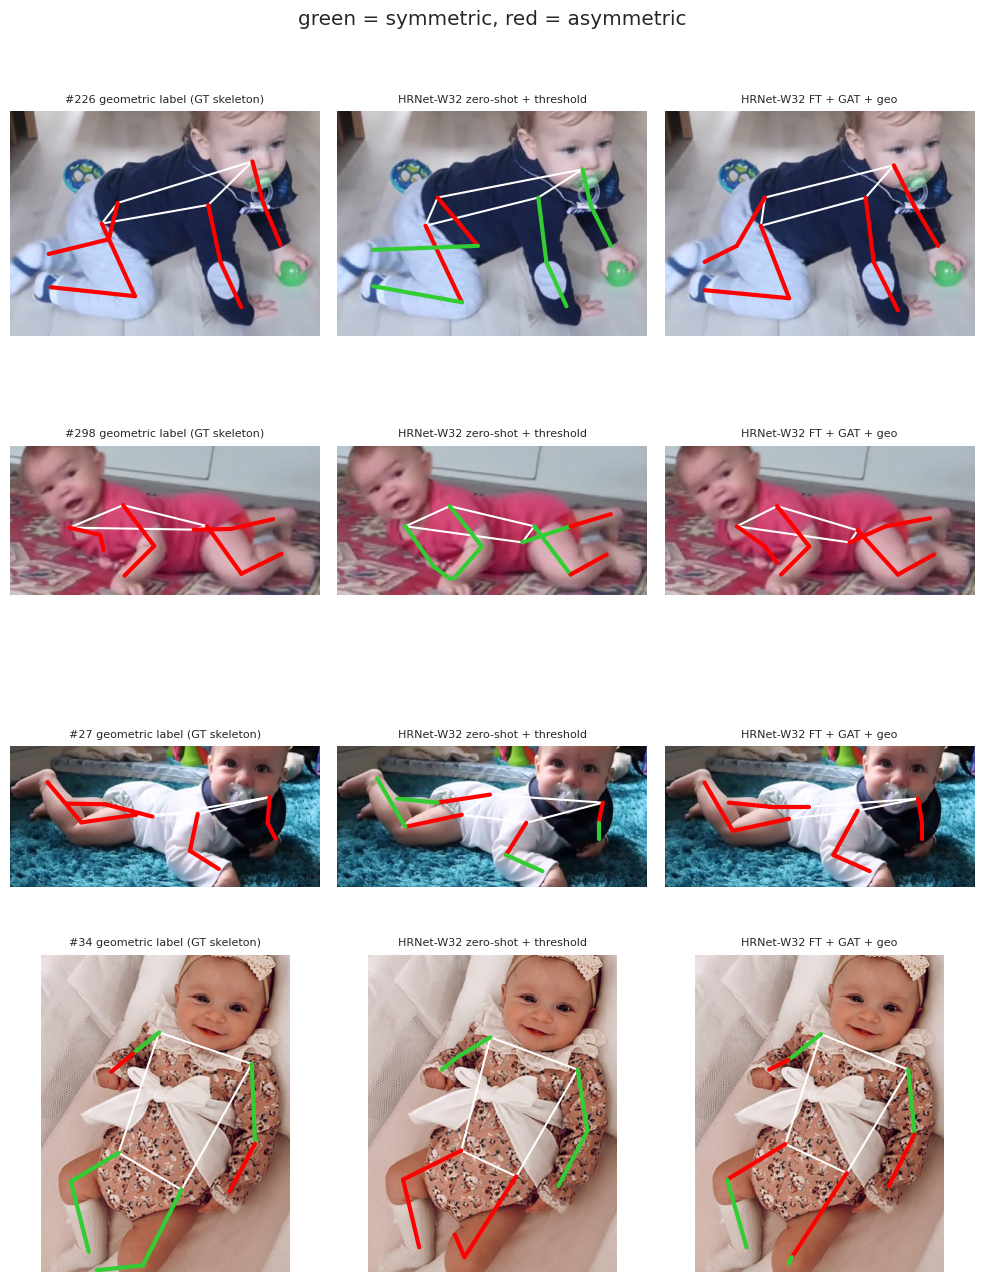

In [31]:
from PIL import Image
LIMB_DRAW = {0: [(5, 7), (6, 8)], 1: [(7, 9), (8, 10)], 2: [(11, 13), (12, 14)], 3: [(13, 15), (14, 16)]}

def draw(ax, i, kp, sym4, title):
    ax.imshow(Image.open(META.img_path[i]).convert("RGB")); ax.axis("off")
    for a, b in [(5, 6), (11, 12), (5, 11), (6, 12)]:
        ax.plot(*kp[[a, b]].T, color="white", lw=1.5)
    for l, segs in LIMB_DRAW.items():
        for a, b in segs:
            ax.plot(*kp[[a, b]].T, color="limegreen" if sym4[l] else "red", lw=3)
    x0, y0, w, h = META.bbox[i]; ax.set_xlim(x0, x0 + w); ax.set_ylim(y0 + h, y0)
    ax.set_title(title, fontsize=8)

if BASE in RESULTS and "BEST" in globals():
    b_ok = (RESULTS[BASE]["pred_sym"] == y_sym).reshape(N_IMG, 4).sum(1)
    n_ok = (RESULTS[BEST]["pred_sym"] == y_sym).reshape(N_IMG, 4).sum(1)
    ex = np.argsort(-(n_ok - b_ok))[:4]
    fig, axes = plt.subplots(len(ex), 3, figsize=(10, 3.2 * len(ex)))
    for r, i in enumerate(ex):
        draw(axes[r, 0], i, GT_KP[i, :, :2], y_sym.reshape(N_IMG, 4)[i], f"#{i} {LABEL_MODE} label (GT skeleton)")
        draw(axes[r, 1], i, POSE2D[BASE[0]]["kp"][i], RESULTS[BASE]["pred_sym"].reshape(N_IMG, 4)[i], f"{BASE[0]} + threshold")
        draw(axes[r, 2], i, POSE2D[BEST[0]]["kp"][i], RESULTS[BEST]["pred_sym"].reshape(N_IMG, 4)[i], f"{BEST[0]} + {BEST[1]}")
    plt.suptitle("green = symmetric, red = asymmetric", y=1.0); plt.tight_layout()
    plt.savefig(FIG / "qualitative.png", dpi=130); plt.show()

In [32]:
summary = {"label mode": LABEL_MODE, "images / folds": f"{N_IMG} / {N_FOLDS}"}
if HAVE_SURVEY:
    summary["Krippendorff α (symmetry / angle)"] = f"{rel.iloc[0, 0]:.2f} / {rel.iloc[0, 1]:.2f}"
if len(POSE_METRICS):
    t5 = POSE_METRICS[POSE_METRICS.subset == "SyRIP test500"].set_index("source")
    for s in t5.index:
        summary[f"pose AP / PCK@0.05 on test500 — {s}"] = f"{t5.loc[s, 'AP']:.3f} / {t5.loc[s, 'PCK@0.05']:.3f}"
if BASE in RESULTS:
    summary[f"baseline AUROC ({BASE[0]} + threshold, OOF)"] = f"{roc_auc_score(y_sym, RESULTS[BASE]['score_sym']):.3f}"
if "BEST" in globals():
    r = RESULTS[BEST]
    summary[f"best: {BEST[0]} + {BEST[1]}"] = (f"AUROC {roc_auc_score(y_sym, r['score_sym']):.3f}, "
                                               f"κ {cohen_kappa_score(y_sym, r['pred_sym']):.3f}, "
                                               f"κw(angle) {cohen_kappa_score(y_ang, r['pred_ang'], weights='quadratic'):.3f}")
for k, v in summary.items():
    print(f"{k:60s} {v}")
json.dump(summary, open(OUT / "summary.json", "w"), indent=2)
print("\nall tables in", OUT, "| figures in", FIG)

label mode                                                   geometric
images / folds                                               700 / 5
pose AP / PCK@0.05 on test500 — HRNet-W32 FT                 0.909 / 0.872
pose AP / PCK@0.05 on test500 — HRNet-W32 zero-shot          0.853 / 0.827
pose AP / PCK@0.05 on test500 — RTMPose-S FT                 0.878 / 0.841
pose AP / PCK@0.05 on test500 — RTMPose-S zero-shot          0.799 / 0.778
baseline AUROC (HRNet-W32 zero-shot + threshold, OOF)        0.840
best: HRNet-W32 FT + GAT + geo                               AUROC 0.894, κ 0.609, κw(angle) 0.688

all tables in /home/dpraju90/scratch/infant_symmetry/outputs | figures in /home/dpraju90/scratch/infant_symmetry/figures


## 15. Deployment: ONNX export, ONNX Runtime and TensorRT
The fine-tuned pose networks (fold-0 checkpoints) are exported to ONNX and run with ONNX Runtime (CUDA) and a
TensorRT FP16 engine. Pre- and post-processing are MMPose's own, so only the network backend changes. We measure
batch-1 latency, batch-32 throughput (GPU input → CPU output, identical for all backends) and accuracy parity
(PCK@0.05 on the fold-0 held-out images, and keypoint deviation from PyTorch FP32). Flip-test is off everywhere.

In [36]:
DEPLOY_FOLD, BENCH_BATCH, MAX_BATCH = 0, 32, 32
DEPLOY_DIR = PROJECT / "deploy"; DEPLOY_DIR.mkdir(exist_ok=True)
try:
    import onnx, onnxruntime as ort
    HAVE_ORT = True
except ImportError:
    HAVE_ORT = False
try:
    import tensorrt as trt
    HAVE_TRT = True
except ImportError:
    HAVE_TRT = False
print("onnxruntime:", HAVE_ORT and (ort.__version__, ort.get_available_providers()),
      "| tensorrt:", HAVE_TRT and trt.__version__,
      "| GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else None)

def load_ft_model(m, k=DEPLOY_FOLD):
    from mmengine.config import Config
    from mmpose.apis import init_model
    cfg = Config.fromfile(str(PROJECT / "configs" / f"{m}_fold{k}.py"))
    best = sorted(Path(cfg.work_dir).glob("best_coco_AP*.pth"))[-1]
    model = init_model(cfg, str(best), device=DEVICE).eval()
    model.test_cfg["flip_test"] = False
    return model

class PoseNet(torch.nn.Module):
    """Backbone + neck + head only (what gets exported); always returns a tuple of tensors."""
    def __init__(self, est):
        super().__init__()
        self.est = est
    def forward(self, x):
        out = self.est.head.forward(self.est.extract_feat(x))
        return tuple(out) if isinstance(out, (tuple, list)) else (out,)

@torch.no_grad()
def preprocess(model, idx):
    """MMPose test pipeline + data preprocessor -> normalized GPU tensor and data samples (GT boxes, as elsewhere)."""
    from mmengine.dataset import Compose, pseudo_collate
    pipe = Compose(model.cfg.test_dataloader.dataset.pipeline)
    items = []
    for i in idx:
        x0, y0, w, h = META.bbox[i]
        d = dict(img_path=META.img_path[i], bbox=np.array([[x0, y0, x0 + w, y0 + h]], np.float32),
                 bbox_score=np.ones(1, np.float32))
        d.update(model.dataset_meta)
        items.append(pipe(d))
    batch = model.data_preprocessor(pseudo_collate(items), False)
    return batch["inputs"].float().contiguous(), batch["data_samples"]

@torch.no_grad()
def decode(model, outputs, data_samples):
    """Network outputs -> keypoints/scores in image coordinates, using MMPose's own codec."""
    outs = outputs[0] if len(outputs) == 1 else tuple(outputs)
    preds = model.head.decode(outs)
    res = model.add_pred_to_datasample(preds, None, copy.deepcopy(data_samples))
    return (np.stack([r.pred_instances.keypoints[0] for r in res]),
            np.stack([r.pred_instances.keypoint_scores[0] for r in res]))

def export_onnx(model, path, H, W):
    net = PoseNet(model).eval()
    dummy = torch.randn(1, 3, H, W, device=DEVICE)
    with torch.no_grad():
        n_out = len(net(dummy))
    out_names = [f"out{j}" for j in range(n_out)]
    kw = dict(input_names=["input"], output_names=out_names, opset_version=17,
              dynamic_axes={"input": {0: "batch"}, **{o: {0: "batch"} for o in out_names}})
    try:
        torch.onnx.export(net, dummy, str(path), dynamo=False, **kw)   # TorchScript-based exporter
    except TypeError:
        torch.onnx.export(net, dummy, str(path), **kw)
    onnx.checker.check_model(str(path))
    return path

class ORTRunner:
    def __init__(self, path):
        so = ort.SessionOptions()
        so.intra_op_num_threads = len(os.sched_getaffinity(0))   # cores this job may use, not the whole node
        so.inter_op_num_threads = 1
        so.log_severity_level = 3                                 # errors only
        prov = [p for p in ["CUDAExecutionProvider", "CPUExecutionProvider"] if p in ort.get_available_providers()]
        self.sess = ort.InferenceSession(str(path), sess_options=so, providers=prov)
        self.provider = self.sess.get_providers()[0]
    def __call__(self, x):                                   # x: GPU float32 tensor -> tuple of CPU tensors
        if self.provider == "CUDAExecutionProvider":
            io = self.sess.io_binding()
            io.bind_input("input", "cuda", 0, np.float32, list(x.shape), x.data_ptr())
            for o in self.sess.get_outputs():
                io.bind_output(o.name, "cuda")
            self.sess.run_with_iobinding(io)
            return tuple(torch.from_numpy(o) for o in io.copy_outputs_to_cpu())
        return tuple(torch.from_numpy(o) for o in self.sess.run(None, {"input": x.cpu().numpy()}))

TRT_LOGGER = trt.Logger(trt.Logger.ERROR) if HAVE_TRT else None   # one shared logger (silences the logger warnings)

class TRTRunner:
    def __init__(self, onnx_path, engine_path, H, W, fp16=True, max_batch=MAX_BATCH, fp32_name_filter="head"):
        if engine_path.exists():
            data = engine_path.read_bytes()
        else:
            builder = trt.Builder(TRT_LOGGER)
            flags = 0
            if int(trt.__version__.split(".")[0]) < 10:
                flags = 1 << int(trt.NetworkDefinitionCreationFlag.EXPLICIT_BATCH)
            network = builder.create_network(flags)
            parser = trt.OnnxParser(network, TRT_LOGGER)
            if not parser.parse(onnx_path.read_bytes()):
                raise RuntimeError("\n".join(str(parser.get_error(i)) for i in range(parser.num_errors)))
            config = builder.create_builder_config()
            config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 2 << 30)
            if fp16:
                config.set_flag(trt.BuilderFlag.FP16)
                if fp32_name_filter:                      # keep the prediction head in FP32 (FP16 overflows in its norms)
                    filters = (fp32_name_filter,) if isinstance(fp32_name_filter, str) else tuple(fp32_name_filter)
                    config.set_flag(trt.BuilderFlag.OBEY_PRECISION_CONSTRAINTS)
                    n = 0
                    for i in range(network.num_layers):
                        L = network.get_layer(i)
                        if any(f in L.name for f in filters) and L.num_outputs and L.get_output(0).dtype == trt.float32:
                            L.precision = trt.float32
                            for j in range(L.num_outputs):
                                L.set_output_type(j, trt.float32)
                            n += 1
                    print(f"  TensorRT: {n} head layers kept in FP32, rest FP16")
            prof = builder.create_optimization_profile()
            prof.set_shape("input", (1, 3, H, W), (max_batch, 3, H, W), (max_batch, 3, H, W))
            config.add_optimization_profile(prof)
            ser = builder.build_serialized_network(network, config)
            if ser is None:
                raise RuntimeError("TensorRT engine build failed")
            data = bytes(ser)
            engine_path.write_bytes(data)
        self.engine = trt.Runtime(TRT_LOGGER).deserialize_cuda_engine(data)
        self.ctx = self.engine.create_execution_context()
        names = [self.engine.get_tensor_name(i) for i in range(self.engine.num_io_tensors)]
        # match the ONNX output order (out0, out1, ...) explicitly instead of trusting the engine's order
        self.outs = sorted((n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.OUTPUT),
                           key=lambda s: int(s[3:]) if s[3:].isdigit() else s)
        print("  TensorRT outputs:", self.outs)
        self.stream = torch.cuda.Stream()                 # non-default stream (removes the enqueueV3 warning)
    def __call__(self, x):                                # x: GPU float32 tensor -> tuple of CPU tensors
        self.stream.wait_stream(torch.cuda.current_stream())
        with torch.cuda.stream(self.stream):
            self.ctx.set_input_shape("input", tuple(x.shape))
            self.ctx.set_tensor_address("input", x.data_ptr())
            res = []
            for n in self.outs:
                dt = torch.from_numpy(np.empty(0, dtype=trt.nptype(self.engine.get_tensor_dtype(n)))).dtype
                t = torch.empty(tuple(self.ctx.get_tensor_shape(n)), dtype=dt, device="cuda")
                self.ctx.set_tensor_address(n, t.data_ptr())
                res.append(t)
            self.ctx.execute_async_v3(self.stream.cuda_stream)
        self.stream.synchronize()
        return tuple(r.float().cpu() for r in res)

onnxruntime: ('1.23.2', ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']) | tensorrt: 10.13.3.9.post1 | GPU: NVIDIA A100-SXM4-40GB MIG 3g.20gb


In [37]:
def bench(fn, x, warm=20, iters=100):
    for _ in range(warm):
        fn(x)
    torch.cuda.synchronize(); t0 = time.perf_counter()
    for _ in range(iters):
        fn(x)
    torch.cuda.synchronize()
    return (time.perf_counter() - t0) / iters

DEPLOY_ROWS = []
if HAVE_MMPOSE and DEVICE == "cuda" and HAVE_ORT:
    test_idx = np.where(FOLD == DEPLOY_FOLD)[0]
    for m in POSE_MODELS:
        model = load_ft_model(m)
        X, samples = preprocess(model, test_idx)                  # (n, 3, H, W) on GPU
        H, W = X.shape[2:]
        onnx_path = export_onnx(model, DEPLOY_DIR / f"{m}_fold{DEPLOY_FOLD}.onnx", H, W)
        net = PoseNet(model).eval()

        backends = {}
        def torch_fp32(x, net=net):
            with torch.no_grad():
                return tuple(o.float().cpu() for o in net(x))
        def torch_fp16(x, net=net):
            with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
                return tuple(o.float().cpu() for o in net(x))
        backends["PyTorch FP32"], backends["PyTorch FP16 (autocast)"] = torch_fp32, torch_fp16
        ortr = ORTRunner(onnx_path)
        backends[f"ONNX Runtime ({ortr.provider.replace('ExecutionProvider', '')})"] = ortr
        if HAVE_TRT:
            try:
                backends["TensorRT FP16"] = TRTRunner(onnx_path, DEPLOY_DIR / f"{m}_fold{DEPLOY_FOLD}_fp16_headfp32_v2.engine", H, W,
                fp32_name_filter=("/final_layer", "/mlp", "/gau", "/cls_x", "/cls_y"))
            except Exception as e:
                print(f"TensorRT build failed for {m}: {e}")

        ref_kp = None
        for name, fn in backends.items():
            outs = [fn(X[s:s + MAX_BATCH]) for s in range(0, len(X), MAX_BATCH)]
            outs = tuple(torch.cat([o[j] for o in outs]) for j in range(len(outs[0])))
            kp, sc = decode(model, outs, samples)
            full = np.zeros((N_IMG, 17, 2)); full[test_idx] = kp
            if ref_kp is None:
                ref_kp = kp
            dev = np.linalg.norm(kp - ref_kp, axis=2)
            xb1 = X[:1].clone()
            xbB = X[:BENCH_BATCH].clone() if len(X) >= BENCH_BATCH else X.repeat(math.ceil(BENCH_BATCH / len(X)), 1, 1, 1)[:BENCH_BATCH]
            DEPLOY_ROWS.append({
                "model": m, "backend": name,
                "latency bs1 (ms)": 1000 * bench(fn, xb1),
                f"throughput bs{BENCH_BATCH} (img/s)": BENCH_BATCH / bench(fn, xbB, warm=5, iters=30),
                "PCK@0.05": np.nanmean(pck(full, test_idx, 0.05)),
                "mean |Δkp| vs FP32 (px)": dev.mean(), "max |Δkp| (px)": dev.max()})
            print(f"{m:10s} {name:28s} done")
        print(f"{m}: ONNX {onnx_path.stat().st_size / 1e6:.1f} MB")
        del model, net, backends; gc.collect(); torch.cuda.empty_cache()

    DEPLOY = pd.DataFrame(DEPLOY_ROWS).set_index(["model", "backend"])
    base = DEPLOY.xs("PyTorch FP32", level="backend")["latency bs1 (ms)"]
    DEPLOY["speed-up vs FP32"] = [base[m] / v for (m, _), v in DEPLOY["latency bs1 (ms)"].items()]
    print(DEPLOY.round(3).to_string())
    DEPLOY.to_csv(OUT / "deployment_benchmark.csv")
else:
    print("needs a GPU session with mmpose + onnxruntime (and tensorrt for the TRT rows)")

Loads checkpoint by local backend from path: /home/dpraju90/scratch/infant_symmetry/work_dirs/RTMPose-S_fold0/best_coco_AP_epoch_84.pth


/tmp/ipykernel_1963629/3907591305.py:68: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(net, dummy, str(path), dynamo=False, **kw)   # TorchScript-based exporter
/tmp/ipykernel_1963629/3907591305.py:119: DeprecationWarning: Use Deprecated in TensorRT 10.12. Superseded by strong typing. instead.
  L.precision = trt.float32
/tmp/ipykernel_1963629/3907591305.py:121: DeprecationWarning: Use Deprecated in TensorRT 10.12. Superseded by strong typing. instead.
  L.set_output_type(j, trt.float32)


  TensorRT: 42 head layers kept in FP32, rest FP16
  TensorRT outputs: ['out0', 'out1']
RTMPose-S  PyTorch FP32                 done
RTMPose-S  PyTorch FP16 (autocast)      done
RTMPose-S  ONNX Runtime (CUDA)          done
RTMPose-S  TensorRT FP16                done
RTMPose-S: ONNX 21.9 MB
Loads checkpoint by local backend from path: /home/dpraju90/scratch/infant_symmetry/work_dirs/HRNet-W32_fold0/best_coco_AP_epoch_80.pth
  TensorRT: 1 head layers kept in FP32, rest FP16
  TensorRT outputs: ['out0']
HRNet-W32  PyTorch FP32                 done
HRNet-W32  PyTorch FP16 (autocast)      done
HRNet-W32  ONNX Runtime (CUDA)          done
HRNet-W32  TensorRT FP16                done
HRNet-W32: ONNX 114.3 MB
                                   latency bs1 (ms)  throughput bs32 (img/s)  PCK@0.05  mean |Δkp| vs FP32 (px)  max |Δkp| (px)  speed-up vs FP32
model     backend                                                                                                                             

In [38]:
# --- diagnose RTMPose + TensorRT: is it FP16 precision, or does even an FP32 engine fail?
m = "RTMPose-S"
model = load_ft_model(m)
X, _ = preprocess(model, np.where(FOLD == DEPLOY_FOLD)[0][:8])
H, W = X.shape[2:]
onnx_path = DEPLOY_DIR / f"{m}_fold{DEPLOY_FOLD}.onnx"
with torch.no_grad():
    ref = [o.float().cpu() for o in PoseNet(model).eval()(X)]

for tag, kw in [("trt_fp32", dict(fp16=False, fp32_name_filter=None)),
                ("trt_fp16", dict(fp16=True,  fp32_name_filter=None))]:
    eng = DEPLOY_DIR / f"diag_{m}_{tag}.engine"
    eng.unlink(missing_ok=True)
    out = TRTRunner(onnx_path, eng, H, W, **kw)(X)
    for j, (a, b) in enumerate(zip(ref, out)):
        print(f"{tag} out{j}: torch {tuple(a.shape)} trt {tuple(b.shape)} | max|diff| {(a - b).abs().max():.4g} | "
              f"non-finite {(~torch.isfinite(b)).sum().item()} | argmax agree {(a.argmax(-1) == b.argmax(-1)).float().mean():.3f} | "
              f"torch range [{a.min():.3g}, {a.max():.3g}] trt range [{b.min():.3g}, {b.max():.3g}]")

# what TensorRT calls the head layers (to see what 'head' matched)
builder = trt.Builder(TRT_LOGGER); net_ = builder.create_network(0); p_ = trt.OnnxParser(net_, TRT_LOGGER)
p_.parse(onnx_path.read_bytes())
names = [net_.get_layer(i).name for i in range(net_.num_layers)]
print(len(names), "layers; last 15:", *names[-15:], sep="\n  ")

Loads checkpoint by local backend from path: /home/dpraju90/scratch/infant_symmetry/work_dirs/RTMPose-S_fold0/best_coco_AP_epoch_84.pth


/home/dpraju90/envs/infsym/lib/python3.11/site-packages/mmengine/runner/checkpoint.py:347: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(filename, map_location=map_location)


  TensorRT outputs: ['out0', 'out1']
trt_fp32 out0: torch (8, 17, 384) trt (8, 17, 384) | max|diff| 0.003092 | non-finite 0 | argmax agree 0.971 | torch range [-2, 1.29] trt range [-2, 1.29]
trt_fp32 out1: torch (8, 17, 512) trt (8, 17, 512) | max|diff| 0.003192 | non-finite 0 | argmax agree 0.985 | torch range [-1.8, 1.35] trt range [-1.8, 1.35]
  TensorRT outputs: ['out0', 'out1']
trt_fp16 out0: torch (8, 17, 384) trt (8, 17, 384) | max|diff| nan | non-finite 52224 | argmax agree 0.000 | torch range [-2, 1.29] trt range [nan, nan]
trt_fp16 out1: torch (8, 17, 512) trt (8, 17, 512) | max|diff| nan | non-finite 69632 | argmax agree 0.000 | torch range [-1.8, 1.35] trt range [nan, nan]
278
  layers; last 15:
  /gau/MatMul_1
  /gau/Mul_2
  onnx::MatMul_634
  ONNXTRT_Broadcast_89
  /gau/o/MatMul
  est.head.gau.res_scale.scale
  ONNXTRT_Broadcast_91
  /gau/res_scale/Mul
  /gau/Add_1
  onnx::MatMul_635
  ONNXTRT_Broadcast_93
  /cls_x/MatMul
  onnx::MatMul_636
  ONNXTRT_Broadcast_96
  /cls_y